## Cell 0: setup, and check that the saved folds match the module

In [5]:
# 08_train - Cell 0: setup; frozen folds must equal the module's rebuild
from pathlib import Path
import json, time, yaml
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, average_precision_score
from circmtl.graph import GraphData, RELS, AUX

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
with open(PROJECT_ROOT / "configs" / "paths.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
D = PROJECT_ROOT / cfg["outputs"]["processed_dir"] / "dataset_v1"
G = D / "graph"
gd = GraphData(D, G)
device = "cuda" if torch.cuda.is_available() else "cpu"

for s in range(3):
    for k in range(5):
        a, b = gd.load_fold(s, k), gd.build_fold(s, k)
        for key in b:
            if key in ("seed", "fold"):
                continue
            same = np.allclose(a[key], b[key]) if b[key].dtype.kind == "f" else np.array_equal(a[key], b[key])
            assert same, f"seed {s} fold {k}: saved '{key}' differs from the module"
print(f"device {device} | nodes {gd.N} | frozen folds = module rebuild on all 15")

device cuda | nodes {'circRNA': 1582, 'disease': 207, 'mirna': 416, 'rbp': 225} | frozen folds = module rebuild on all 15


## Cell 1: the model (RGCN encoder, DistMult decoders)

In [17]:
# 08_train - Cell 1: model
from torch_geometric.nn import RGCNConv

class CircMTL(nn.Module):
    """Input projections -> 2-layer RGCN (6 relations: 3 forward + 3 reverse) -> DistMult per forward relation."""
    def __init__(self, N, in_dim, hidden=128, layers=2, num_bases=3, dropout=0.2):
        super().__init__()
        self.proj = nn.Linear(in_dim, hidden)                                    # circRNA features
        self.emb = nn.ModuleDict({t: nn.Embedding(N[t], hidden) for t in ("disease", "mirna", "rbp")})
        for e in self.emb.values():
            nn.init.normal_(e.weight, std=0.1)
        self.convs = nn.ModuleList([RGCNConv(hidden, hidden, num_relations=2 * len(RELS), num_bases=num_bases)
                                    for _ in range(layers)])
        self.rel = nn.ParameterDict({r: nn.Parameter(torch.full((hidden,), 0.1)) for r in RELS})   # small start: loss begins near ln 2   # DistMult diagonals
        self.dropout = dropout

    def encode(self, x, edge_index, edge_type):
        # node order must match GraphData.offset: circRNA, disease, mirna, rbp
        h = torch.cat([self.proj(x), self.emb["disease"].weight, self.emb["mirna"].weight, self.emb["rbp"].weight], 0)
        h = F.dropout(h, self.dropout, self.training)
        for i, conv in enumerate(self.convs):
            h = conv(h, edge_index, edge_type)
            if i < len(self.convs) - 1:
                h = F.dropout(F.relu(h), self.dropout, self.training)
        return h

    def score(self, h, r, gpairs):
        return (h[gpairs[:, 0]] * self.rel[r] * h[gpairs[:, 1]]).sum(-1)

c:\Users\aeasa\anaconda3\envs\circmtl\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\aeasa\anaconda3\envs\circmtl\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Cell 2: training and evaluation functions

In [15]:
# 08_train - Cell 2: training loop, early stopping on validation disease AUROC, evaluation
TRAIN = dict(hidden=128, num_bases=3, dropout=0.2, lr=1e-3, weight_decay=1e-4,
             max_epochs=300, warmup=20, min_epochs=60, patience=40, neg_k=5)
HEADS = {"M1": ["disease"], "M2": ["disease"], "M3": ["disease", "mirna", "rbp"],
         "M3-RBP": ["disease", "rbp"], "M3-miRNA": ["disease", "mirna"]}
graph_of = lambda m: "M1" if m == "M1" else "M3"          # M1: disease-only graph; all others: full graph

def T(a):
    return torch.from_numpy(a).to(device)

def bce_balanced(s_pos, s_neg):
    return 0.5 * (F.binary_cross_entropy_with_logits(s_pos, torch.ones_like(s_pos)) +
                  F.binary_cross_entropy_with_logits(s_neg, torch.zeros_like(s_neg)))

def score_pairs(model, h, r, pos, neg):
    with torch.no_grad():
        sp = model.score(h, r, T(gd.global_pairs(r, pos))).cpu().numpy()
        sn = model.score(h, r, T(gd.global_pairs(r, neg))).cpu().numpy()
    y, s = np.r_[np.ones(len(sp)), np.zeros(len(sn))], np.r_[sp, sn]
    return roc_auc_score(y, s), average_precision_score(y, s), sp, sn

def train_one(fd, model_name, aux_w=0.5, seed=0, cfg=TRAIN):
    torch.manual_seed(seed)
    rng_split = np.random.default_rng(seed)                                       # same graphs for M2 and M3
    rng_neg = {r: np.random.default_rng(seed + 1 + i) for i, r in enumerate(RELS)} # same disease negatives too
    gm = graph_of(model_name)
    w = {r: (1.0 if r == "disease" else aux_w) for r in HEADS[model_name]}
    x = T(gd.features(fd))
    model = CircMTL(gd.N, x.shape[1], cfg["hidden"], num_bases=cfg["num_bases"], dropout=cfg["dropout"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    val_ei, val_et = gd.to_edge_tensors(gd.inference_graph(fd, "val", gm), device)
    best, hist = {"auc": -1.0, "epoch": 0, "state": None}, []
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        mp, sup = gd.epoch_graph(fd, rng_split, gm)
        ei, et = gd.to_edge_tensors(mp, device)
        h = model.encode(x, ei, et)
        loss, parts = 0.0, {}
        for r, wr in w.items():
            neg = gd.train_negatives(r, sup[r], fd[f"{r}_train"], rng_neg[r], k=cfg["neg_k"])
            l = bce_balanced(model.score(h, r, T(gd.global_pairs(r, sup[r]))), model.score(h, r, T(gd.global_pairs(r, neg))))
            loss, parts[r] = loss + wr * l, l.item()
        opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            va = score_pairs(model, model.encode(x, val_ei, val_et), "disease", fd["disease_val"], fd["neg_val"])[0]
        hist.append({"epoch": epoch, "loss": float(loss), **{f"loss_{r}": v for r, v in parts.items()}, "val_auc": va})
        sm = float(np.mean([h_["val_auc"] for h_ in hist[-5:]]))           # 5-epoch moving average
        if epoch >= cfg["warmup"] and sm > best["auc"]:                    # ignore noise peaks before warm-up
            best = {"auc": sm, "epoch": epoch, "state": {k: v.detach().clone() for k, v in model.state_dict().items()}}
        elif epoch >= cfg["min_epochs"] and epoch - best["epoch"] >= cfg["patience"]:
            break
        elif epoch - best["epoch"] >= cfg["patience"]:
            break
    model.load_state_dict(best["state"]); model.eval()
    return model, x, pd.DataFrame(hist), best

def evaluate(model, x, fd, model_name):
    """Disease: test circRNAs WITH their auxiliary edges. Auxiliary heads: WITHOUT (only models trained on that head)."""
    gm, out = graph_of(model_name), {}
    with torch.no_grad():
        hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", gm, with_test_aux=True), device))
        for sc in ("degree_matched", "random"):
            out[f"disease_{sc}_auroc"], out[f"disease_{sc}_aupr"], *_ = score_pairs(model, hA, "disease", fd["disease_test"], fd[f"neg_test_{sc}"])
        aux_heads = [r for r in AUX if r in HEADS[model_name]]
        if aux_heads:
            hB = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", gm, with_test_aux=False), device))
            for r in aux_heads:
                out[f"{r}_auroc"], out[f"{r}_aupr"], *_ = score_pairs(model, hB, r, fd[f"{r}_test"], fd[f"neg_test_{r}"])
    return out

## Cell 3: smoke test, seed 0 fold 0, M1 and M3

In [16]:
# 08_train - Cell 3: smoke test (one fold; checks that everything runs and learns)
fd = gd.load_fold(0, 0)
for m in ("M1", "M3"):
    t0 = time.time()
    model, x, hist, best = train_one(fd, m, aux_w=0.5, seed=0)
    res = evaluate(model, x, fd, m)
    print(f"\n{m}: {time.time() - t0:.0f}s | epochs {len(hist)} | best epoch {best['epoch']} | val AUROC {best['auc']:.3f}")
    print("  test:", {k: round(v, 3) for k, v in res.items()})
    print(hist.iloc[[0, len(hist) // 2, -1]].round(3).to_string(index=False))


M1: 3s | epochs 91 | best epoch 51 | val AUROC 0.539
  test: {'disease_degree_matched_auroc': 0.513, 'disease_degree_matched_aupr': 0.515, 'disease_random_auroc': 0.516, 'disease_random_aupr': 0.483}
 epoch  loss  loss_disease  val_auc
     1 0.710         0.710    0.529
    46 0.651         0.651    0.530
    91 0.567         0.567    0.525

M3: 5s | epochs 72 | best epoch 32 | val AUROC 0.532
  test: {'disease_degree_matched_auroc': 0.507, 'disease_degree_matched_aupr': 0.508, 'disease_random_auroc': 0.487, 'disease_random_aupr': 0.465, 'mirna_auroc': 0.609, 'mirna_aupr': 0.588, 'rbp_auroc': 0.756, 'rbp_aupr': 0.715}
 epoch  loss  loss_disease  loss_mirna  loss_rbp  val_auc
     1 1.447         0.714       0.740     0.726    0.515
    37 1.295         0.663       0.668     0.596    0.512
    72 1.221         0.615       0.662     0.551    0.523


## Cell 4: full runs (M1, M2, M3 × 3 seeds × 5 folds)

In [17]:
# 08_train - Cell 4: full runs - M1, M2, M3 x 3 seeds x 5 folds; M3 auxiliary weight chosen on validation
OUT = D / "train_results"; OUT.mkdir(exist_ok=True)
MODELS = ["M1", "M2", "M3"]                       # optional later: "M3-RBP", "M3-miRNA"
AUX_W = [0.1, 0.5, 1.0]

def _frame(task, scheme, pos, neg, sp, sn):
    return pd.DataFrame({"task": task, "scheme": scheme, "c": np.r_[pos[:, 0], neg[:, 0]], "t": np.r_[pos[:, 1], neg[:, 1]],
                         "y": np.r_[np.ones(len(pos), int), np.zeros(len(neg), int)], "score": np.r_[sp, sn]})

def predict(model, x, fd, model_name):
    """Per-pair test scores: disease WITH test auxiliary edges; auxiliary heads WITHOUT them."""
    gm, parts = graph_of(model_name), []
    with torch.no_grad():
        hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", gm, with_test_aux=True), device))
        for sc in ("degree_matched", "random"):
            _, _, sp, sn = score_pairs(model, hA, "disease", fd["disease_test"], fd[f"neg_test_{sc}"])
            parts.append(_frame("disease", sc, fd["disease_test"], fd[f"neg_test_{sc}"], sp, sn))
        heads = [r for r in AUX if r in HEADS[model_name]]
        if heads:
            hB = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", gm, with_test_aux=False), device))
            for r in heads:
                _, _, sp, sn = score_pairs(model, hB, r, fd[f"{r}_test"], fd[f"neg_test_{r}"])
                parts.append(_frame(r, "degree_matched", fd[f"{r}_test"], fd[f"neg_test_{r}"], sp, sn))
    df = pd.concat(parts, ignore_index=True)
    df["score_rank"] = df.groupby(["task", "scheme"])["score"].rank(pct=True)   # within-run ranks before pooling
    return df

t0, log = time.time(), []
for m in MODELS:
    for s in range(3):
        for k in range(5):
            fn = OUT / f"pred_{m}_seed{s}_fold{k}.csv"
            if fn.exists():
                continue                                                    # resume: finished runs are kept
            fd = gd.load_fold(s, k)
            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            for w in weights:
                model, x, hist, best = train_one(fd, m, aux_w=(w or 0.0), seed=s)
                cands.append((best["auc"], w, model, x, best["epoch"]))
            val_auc, w, model, x, ep = max(cands, key=lambda c: c[0])      # chosen on VALIDATION only
            predict(model, x, fd, m).assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc).to_csv(fn, index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3)})
            print(f"  {m:3s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | {time.time() - t0:5.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUT / "run_log.csv", mode="a", index=False, header=not (OUT / "run_log.csv").exists())
print(f"done in {time.time() - t0:.0f}s")

  M1  seed 0 fold 0 | w None | best epoch 125 | val 0.553 |     5s
  M1  seed 0 fold 1 | w None | best epoch  28 | val 0.527 |     7s
  M1  seed 0 fold 2 | w None | best epoch  62 | val 0.531 |    10s
  M1  seed 0 fold 3 | w None | best epoch  35 | val 0.574 |    12s
  M1  seed 0 fold 4 | w None | best epoch  63 | val 0.551 |    15s
  M1  seed 1 fold 0 | w None | best epoch  64 | val 0.550 |    18s
  M1  seed 1 fold 1 | w None | best epoch  44 | val 0.559 |    20s
  M1  seed 1 fold 2 | w None | best epoch  35 | val 0.522 |    22s
  M1  seed 1 fold 3 | w None | best epoch 118 | val 0.559 |    27s
  M1  seed 1 fold 4 | w None | best epoch  84 | val 0.561 |    30s
  M1  seed 2 fold 0 | w None | best epoch  21 | val 0.519 |    32s
  M1  seed 2 fold 1 | w None | best epoch 145 | val 0.572 |    37s
  M1  seed 2 fold 2 | w None | best epoch  29 | val 0.552 |    39s
  M1  seed 2 fold 3 | w None | best epoch  57 | val 0.567 |    41s
  M1  seed 2 fold 4 | w None | best epoch  20 | val 0.557 |   

## Cell 5: results, paired comparisons, bootstrap over host groups, stratified

In [18]:
# 08_train - Cell 5: results - pooled AUROC on within-run ranks; paired bootstrap over host groups; stratified
P = pd.concat([pd.read_csv(f) for f in sorted(OUT.glob("pred_*.csv"))], ignore_index=True)
status = gd.nodes_c.set_index("circ_idx")["aux_status"].replace({"miRNA_only": "both"})
P["status"] = P["c"].map(status)
KEYS, N_BOOT = ["seed", "fold", "c", "t", "y", "status"], 1000

def wide(task, scheme):
    d = P[(P["task"] == task) & (P["scheme"] == scheme)]
    return d.pivot_table(index=KEYS, columns="model", values="score_rank").reset_index()

def mean_seed_auc(W, col, w=None):
    out = []
    for _, g in W.groupby("seed"):
        ww = None if w is None else w[g.index]
        if ww is not None and ww.sum() == 0:
            continue
        out.append(roc_auc_score(g["y"], g[col], sample_weight=ww))
    return float(np.mean(out))

# 1. Summary per model (mean over seeds; range shows seed-to-seed spread)
summ = []
for m in sorted(P["model"].unique()):
    r = {"model": m}
    for task, sc in (("disease", "degree_matched"), ("disease", "random"), ("mirna", "degree_matched"), ("rbp", "degree_matched")):
        d = P[(P["model"] == m) & (P["task"] == task) & (P["scheme"] == sc)]
        if len(d):
            per = [roc_auc_score(g["y"], g["score_rank"]) for _, g in d.groupby("seed")]
            r[f"{task}_{sc}"] = f"{np.mean(per):.3f} ({min(per):.3f}-{max(per):.3f})"
    summ.append(r)
S = pd.DataFrame(summ)
print(S.to_string(index=False))
print("floors (disease, degree-matched): length only 0.527 | popularity 0.510 | sequence-only probe 0.529")

# 2. Paired comparisons: same test pairs for every model; bootstrap resamples host groups
def compare(a, b, task="disease", scheme="degree_matched", strata=None, n=N_BOOT, seed=0):
    W = wide(task, scheme).dropna(subset=[a, b])
    if strata is not None:
        W = W[W["status"].isin(strata)]
    W = W.reset_index(drop=True)
    ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
    rng, B = np.random.default_rng(seed), []
    for _ in range(n):
        w = np.bincount(rng.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
        B.append((mean_seed_auc(W, a, w), mean_seed_auc(W, b, w)))
    B = np.array(B); dif = B[:, 0] - B[:, 1]
    pa, pb = mean_seed_auc(W, a), mean_seed_auc(W, b)
    lo, hi = np.percentile(dif, [2.5, 97.5])
    return {"comparison": f"{a} - {b}", "strata": "all" if strata is None else "+".join(strata), "n_pairs": len(W),
            "auroc_a": round(pa, 3), "auroc_b": round(pb, 3), "diff": round(pa - pb, 3),
            "ci": f"[{lo:.3f}, {hi:.3f}]", "excludes_0": bool(lo > 0 or hi < 0)}

comps = [compare(a, b, strata=st)
         for a, b in (("M3", "M1"), ("M2", "M1"), ("M3", "M2"))
         for st in (None, ["both"], ["RBP_only"], ["neither"])]
C = pd.DataFrame(comps)
print("\n" + C.to_string(index=False))
S.to_csv(OUT / "summary.csv", index=False); C.to_csv(OUT / "comparisons.csv", index=False)

model disease_degree_matched      disease_random mirna_degree_matched  rbp_degree_matched
   M1    0.521 (0.515-0.525) 0.513 (0.500-0.524)                  NaN                 NaN
   M2    0.520 (0.500-0.535) 0.502 (0.480-0.518)                  NaN                 NaN
   M3    0.530 (0.516-0.543) 0.551 (0.542-0.557)  0.609 (0.605-0.612) 0.740 (0.726-0.752)
floors (disease, degree-matched): length only 0.527 | popularity 0.510 | sequence-only probe 0.529

comparison   strata  n_pairs  auroc_a  auroc_b   diff              ci  excludes_0
   M3 - M1      all    12822    0.530    0.521  0.009 [-0.001, 0.019]       False
   M3 - M1     both     6984    0.531    0.528  0.003 [-0.010, 0.017]       False
   M3 - M1 RBP_only     4068    0.533    0.511  0.021  [0.004, 0.037]        True
   M3 - M1  neither     1770    0.524    0.518  0.006 [-0.022, 0.032]       False
   M2 - M1      all    12822    0.520    0.521 -0.002 [-0.011, 0.008]       False
   M2 - M1     both     6984    0.517    0.528 -

## Cell 6: learning curve - does performance rise with more training circRNAs?

In [19]:
# 08_train - Cell 6: learning curve - does performance rise with more training circRNAs?
def subsample(fd, frac, seed):
    """Keep a fraction of training HOST GROUPS (whole groups); validation and test unchanged."""
    rng = np.random.default_rng(seed)
    g = gd.groups[fd["train"]]
    ug = np.unique(g)
    keep_g = rng.choice(ug, size=max(1, int(round(frac * len(ug)))), replace=False)
    keep = fd["train"][np.isin(g, keep_g)]
    out = dict(fd); out["train"] = keep
    km = np.isin(np.arange(gd.N["circRNA"]), keep)
    for r in RELS:
        out[f"{r}_train"] = fd[f"{r}_train"][km[fd[f"{r}_train"][:, 0]]]
    return out

LC = []
t0 = time.time()
for frac in (0.25, 0.5, 0.75, 1.0):
    for k in range(5):
        fd = subsample(gd.load_fold(0, k), frac, seed=100 + k)
        for m in ("M1", "M3"):
            model, x, hist, best = train_one(fd, m, aux_w=0.5, seed=0)
            p = predict(model, x, fd, m)
            p = p[(p["task"] == "disease") & (p["scheme"] == "degree_matched")]
            LC.append(p.assign(frac=frac, fold=k, model=m, n_train_pairs=len(fd["disease_train"])))
    print(f"  fraction {frac:.2f} done | {time.time() - t0:.0f}s")
LC = pd.concat(LC, ignore_index=True)
curve = (LC.groupby(["model", "frac"])
         .apply(lambda g: pd.Series({"test_AUROC": roc_auc_score(g["y"], g["score_rank"]),
                                     "train_pairs_per_fold": g["n_train_pairs"].mean()}))
         .round(3).reset_index())
print(curve.to_string(index=False))
curve.to_csv(OUT / "learning_curve.csv", index=False)

  fraction 0.25 done | 42s
  fraction 0.50 done | 91s
  fraction 0.75 done | 137s
  fraction 1.00 done | 186s
model  frac  test_AUROC  train_pairs_per_fold
   M1  0.25       0.522               339.830
   M1  0.50       0.521               697.032
   M1  0.75       0.529              1031.821
   M1  1.00       0.527              1375.802
   M3  0.25       0.518               339.830
   M3  0.50       0.525               697.032
   M3  0.75       0.511              1031.821
   M3  1.00       0.518              1375.802


In [20]:
# Is performance limited by disease data? AUROC by the disease's number of training pairs in that fold
deg = {(s, k): np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=gd.N["disease"])
       for s in range(3) for k in range(5)}
d = P[(P["task"] == "disease") & (P["scheme"] == "degree_matched")].copy()
d["dis_train_deg"] = [deg[(s, k)][t] for s, k, t in zip(d["seed"], d["fold"], d["t"])]
d["bin"] = pd.cut(d["dis_train_deg"], [-1, 2, 9, 49, 10**9], labels=["0-2", "3-9", "10-49", "50+"])
tab = (d.groupby(["model", "bin"], observed=True)
        .apply(lambda g: pd.Series({"pairs": len(g), "positives": int(g["y"].sum()),
                                    "AUROC": roc_auc_score(g["y"], g["score_rank"]) if g["y"].nunique() == 2 else np.nan}))
        .round(3).reset_index())
print(tab.to_string(index=False))

model   bin  pairs  positives  AUROC
   M1   0-2 1301.0      706.0  0.557
   M1   3-9 3060.0     1457.0  0.498
   M1 10-49 4909.0     2376.0  0.528
   M1   50+ 3552.0     1872.0  0.504
   M2   0-2 1301.0      706.0  0.538
   M2   3-9 3060.0     1457.0  0.512
   M2 10-49 4909.0     2376.0  0.516
   M2   50+ 3552.0     1872.0  0.505
   M3   0-2 1301.0      706.0  0.572
   M3   3-9 3060.0     1457.0  0.508
   M3 10-49 4909.0     2376.0  0.540
   M3   50+ 3552.0     1872.0  0.503


-----------------------------------------------------------------------------------------

## Cell 7

**Objective:** replace only the disease input with the MeSH similarity rows, keep everything else identical, and check on seed 0, fold 0 that it runs, learns and is aligned with the graph's disease index.

In [21]:
# 08_train - Cell 7: Extension A (post hoc, configs/graph_ext.yaml) - MeSH disease input; smoke test seed 0 fold 0
import contextlib

G = D / "new_graph"
EXT = G / "disease_ext"
MESH = torch.from_numpy(np.load(EXT / "disease_feat_mesh.npy")).float()      # (207, 207): MeSH similarity row per disease
HAS = torch.from_numpy(np.load(EXT / "disease_feat_mask.npy")).bool()        # True for the 200 diseases with features
assert MESH.shape == (gd.N["disease"], gd.N["disease"]) and HAS.shape[0] == gd.N["disease"]

# the graph's disease index must follow the disease_id order used to build the features
dtab = pd.read_csv(D / "diseases.csv").sort_values("disease_id")
npairs = pd.read_csv(D / "cda_pairs.csv").groupby("disease").size().reindex(dtab["disease"]).fillna(0).astype(int).values
fd = gd.load_fold(0, 0)
cnt = np.bincount(np.r_[fd["disease_train"][:, 1], fd["disease_val"][:, 1], fd["disease_test"][:, 1]], minlength=gd.N["disease"])
bad = np.where(cnt != npairs)[0]
print(f"disease index check: {len(bad)} mismatches", bad[:10].tolist())
assert len(bad) == 0, "graph disease index differs from disease_id order - features would be misaligned"

class CircMTLMesh(CircMTL):
    """Same model; disease input = Linear(207 -> hidden) on the MeSH similarity row.
    A learned embedding is kept only for the diseases without features (5 non-disease concepts, 2 unmapped)."""
    def __init__(self, N, in_dim, hidden=128, layers=2, num_bases=3, dropout=0.2):
        super().__init__(N, in_dim, hidden, layers, num_bases, dropout)
        self.register_buffer("mesh", MESH.clone())
        self.register_buffer("has", HAS.clone())
        self.mesh_proj = nn.Linear(MESH.shape[1], hidden)

    def encode(self, x, edge_index, edge_type):
        d = torch.where(self.has.unsqueeze(1), self.mesh_proj(self.mesh), self.emb["disease"].weight)
        h = torch.cat([self.proj(x), d, self.emb["mirna"].weight, self.emb["rbp"].weight], 0)
        h = F.dropout(h, self.dropout, self.training)
        for i, conv in enumerate(self.convs):
            h = conv(h, edge_index, edge_type)
            if i < len(self.convs) - 1:
                h = F.dropout(F.relu(h), self.dropout, self.training)
        return h

@contextlib.contextmanager
def use_model(cls):
    """train_one builds CircMTL(...) by name; swap the name for the duration of a run, then restore it."""
    global CircMTL
    old, CircMTL = CircMTL, cls
    try:
        yield
    finally:
        CircMTL = old

# smoke test: identical seed, fold, auxiliary weight and schedule
rows = {}
for name, cls in (("M3", CircMTL), ("M3_mesh", CircMTLMesh)):
    t0 = time.time()
    with use_model(cls):
        model, x, hist, best = train_one(fd, "M3", aux_w=0.5, seed=0)
        rows[name] = evaluate(model, x, fd, "M3")
    print(f"{name}: {time.time() - t0:.0f}s | epochs {len(hist)} | best epoch {best['epoch']} | val AUROC {best['auc']:.3f} | "
          f"final loss {hist['loss'].iloc[-1]:.3f}")
assert CircMTL.__name__ == "CircMTL", "the model name was not restored"

R = pd.DataFrame(rows).T.round(3)
R.loc["diff"] = (R.loc["M3_mesh"] - R.loc["M3"]).round(3)
print("\n", R[[c for c in R.columns if c.endswith("auroc")]].to_string())

print("\n===== OBSERVATIONS =====")
print(f"index mismatches={len(bad)}; " + "; ".join(
    f"{k}: disease_dm {v['disease_degree_matched_auroc']:.3f}, disease_rand {v['disease_random_auroc']:.3f}, "
    f"mirna {v.get('mirna_auroc', float('nan')):.3f}, rbp {v.get('rbp_auroc', float('nan')):.3f}" for k, v in rows.items()))

disease index check: 0 mismatches []
M3: 7s | epochs 72 | best epoch 32 | val AUROC 0.532 | final loss 1.221
M3_mesh: 8s | epochs 98 | best epoch 58 | val AUROC 0.552 | final loss 1.167

          disease_degree_matched_auroc  disease_random_auroc  mirna_auroc  rbp_auroc
M3                              0.508                 0.487        0.610      0.756
M3_mesh                         0.493                 0.547        0.625      0.784
diff                           -0.015                 0.060        0.015      0.028

===== OBSERVATIONS =====
index mismatches=0; M3: disease_dm 0.508, disease_rand 0.487, mirna 0.610, rbp 0.756; M3_mesh: disease_dm 0.493, disease_rand 0.547, mirna 0.625, rbp 0.784


**Interpretation:**

- The alignment check passed: 0 mismatches, so the 207 feature rows match the graph's disease index.
- Both variants train. M3_mesh reached a higher validation AUROC (0.552 against 0.532), stopped later (best epoch 58 against 32) and ended at a lower training loss (1.167 against 1.221, taken at the last epoch, not the best one).
- On this one fold and seed, the test AUROCs move in mixed directions. The degree-matched disease AUROC went from 0.508 to 0.493 (−0.015). The random-negative AUROC went from 0.487 to 0.547 (+0.060). miRNA went from 0.610 to 0.625 and RBP from 0.756 to 0.784. None of this is interpretable from one fold.

**Decision:** the smoke test passes. Run the full set.

## Cell 8

**Objective:** train M1_mesh, M2_mesh and M3_mesh on all 3 seeds × 5 folds, with the same seeds, graphs, negatives, schedule, model selection on validation, and auxiliary-weight grid as the main models. Predictions are saved next to the main ones.

In [22]:
# 08_train - Cell 8: Extension A full runs - M1_mesh, M2_mesh, M3_mesh x 3 seeds x 5 folds (post hoc, configs/graph_ext.yaml)
for m in ("M1", "M2", "M3"):                                   # same head sets as the main models
    HEADS[m + "_mesh"] = HEADS[m]
_old_graph_of = graph_of
graph_of = lambda m: "M1" if m.startswith("M1") else "M3"       # M1 variants: disease-only graph; all others: full graph
assert all(graph_of(m) == _old_graph_of(m) for m in ("M1", "M2", "M3", "M3-RBP", "M3-miRNA")), "graph_of changed for the main models"

MESH_MODELS = ["M1_mesh", "M2_mesh", "M3_mesh"]
t0, log = time.time(), []
for m in MESH_MODELS:
    for s in range(3):
        for k in range(5):
            fn = OUT / f"pred_{m}_seed{s}_fold{k}.csv"
            if fn.exists():
                continue                                        # resume: finished runs are kept
            fdk = gd.load_fold(s, k)
            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            with use_model(CircMTLMesh):
                for w in weights:
                    model, x, hist, best = train_one(fdk, m, aux_w=(w or 0.0), seed=s)
                    cands.append((best["auc"], w, model, x, best["epoch"]))
                val_auc, w, model, x, ep = max(cands, key=lambda c: c[0])      # chosen on VALIDATION only
                df = predict(model, x, fdk, m)
            df.assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc).to_csv(fn, index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3)})
            print(f"  {m:8s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | {time.time() - t0:5.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUT / "run_log.csv", mode="a", index=False, header=not (OUT / "run_log.csv").exists())
assert CircMTL.__name__ == "CircMTL", "the model name was not restored"

# completeness and summary, read back from the saved prediction files
meta = pd.concat([pd.read_csv(f, nrows=1)[["model", "seed", "fold", "aux_w", "best_epoch", "val_auc"]]
                  for m in MESH_MODELS for f in sorted(OUT.glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print("\nruns per model:", meta["model"].value_counts().to_dict())
print(meta.groupby("model").agg(runs=("val_auc", "size"), val_auc=("val_auc", "mean"), best_epoch=("best_epoch", "mean")).round(3).to_string())
print("auxiliary weight chosen (M3_mesh):", meta.loc[meta["model"] == "M3_mesh", "aux_w"].value_counts().to_dict())

print("\n===== OBSERVATIONS =====")
print(f"runs={meta['model'].value_counts().to_dict()}; mean val AUROC=" +
      ", ".join(f"{m}: {g['val_auc'].mean():.3f}" for m, g in meta.groupby("model")) +
      f"; time this session={time.time() - t0:.0f}s")

  M1_mesh  seed 0 fold 0 | w None | best epoch  56 | val 0.544 |     3s
  M1_mesh  seed 0 fold 1 | w None | best epoch  25 | val 0.557 |     5s
  M1_mesh  seed 0 fold 2 | w None | best epoch  70 | val 0.540 |     8s
  M1_mesh  seed 0 fold 3 | w None | best epoch 119 | val 0.571 |    12s
  M1_mesh  seed 0 fold 4 | w None | best epoch  38 | val 0.552 |    14s
  M1_mesh  seed 1 fold 0 | w None | best epoch  30 | val 0.584 |    16s
  M1_mesh  seed 1 fold 1 | w None | best epoch  32 | val 0.554 |    18s
  M1_mesh  seed 1 fold 2 | w None | best epoch  85 | val 0.540 |    22s
  M1_mesh  seed 1 fold 3 | w None | best epoch  64 | val 0.548 |    25s
  M1_mesh  seed 1 fold 4 | w None | best epoch  85 | val 0.553 |    28s
  M1_mesh  seed 2 fold 0 | w None | best epoch  20 | val 0.557 |    30s
  M1_mesh  seed 2 fold 1 | w None | best epoch  54 | val 0.577 |    32s
  M1_mesh  seed 2 fold 2 | w None | best epoch  64 | val 0.562 |    35s
  M1_mesh  seed 2 fold 3 | w None | best epoch  44 | val 0.564 |

**Interpretation:**

- All 45 runs completed (15 per model), in 416 s. That is faster than my estimate of 10-15 minutes.
- Mean validation AUROC rose from 0.557 (M1_mesh) to 0.559 (M2_mesh) to 0.567 (M3_mesh). This ordering matches your main models, but it is not yet a result. Each run's validation AUROC is the best value reached during training, so it is optimistic. M3_mesh's is more so, because it takes the best of three auxiliary weights while M1_mesh and M2_mesh have one candidate. The main models need the same caveat, and the next cell prints their validation values from the same files.
- The auxiliary weight chosen for M3_mesh was 1.0 in 8 of 15 runs, 0.1 in 4 and 0.5 in 3. Validation picks the largest weight about half the time, but with differences of this size that is weak evidence.

**Decision:** compare against the main models using the rule fixed in graph_ext.yaml, with no further training.

In [29]:
# 08_train - Cell 9: Extension A - paired comparisons (rule fixed beforehand in configs/graph_ext.yaml)

# 08_train - Cell 9, new first block: read configs/graph_ext.yaml and check that the code follows it
EXT_YAML = PROJECT_ROOT / "configs" / "graph_ext.yaml"
ext = yaml.safe_load(EXT_YAML.read_text(encoding="utf-8"))

# 1. clarification of the keep rule, logged before the all-fold comparison (appended once; wording fixed below)
if "clarification" not in ext:
    with open(EXT_YAML, "a", encoding="utf-8") as f:
        f.write(
            "\nclarification:   # added after the Cell 8 runs finished, before any test-set comparison was computed\n"
            "  keep_features_if: \"M3_mesh - M3 on degree-matched disease AUROC is POSITIVE and its 95% bootstrap CI over host groups excludes 0\"\n"
            "  reason: \"the original wording would also pass a significantly negative difference; the intent was a gain\"\n")
    ext = yaml.safe_load(EXT_YAML.read_text(encoding="utf-8"))

txt = EXT_YAML.read_text(encoding="utf-8")
OLD = "before any test-set comparison was computed"
NEW = ("and before the all-fold test comparison; the single-fold smoke test (Cell 7, seed 0 fold 0) "
       "had printed test AUROCs earlier, and the decision to run all folds did not depend on them")
if OLD in txt:
    EXT_YAML.write_text(txt.replace(OLD, NEW), encoding="utf-8")
    ext = yaml.safe_load(EXT_YAML.read_text(encoding="utf-8"))
print("clarification note:", ext["clarification"]["keep_features_if"])

# 2. the code must match the file
MESH_MODELS = ["M1_mesh", "M2_mesh", "M3_mesh"]
assert ext["variants"] == MESH_MODELS, "variants in the yaml differ from the models that were run"
for k in ("disease_mesh_map", "similarity", "feature_file", "negatives"):
    assert (D / ext["frozen_inputs"][k]).exists(), f"missing frozen input: {k}"
print("keep rule :", ext["clarification"]["keep_features_if"])
print("stop rule :", ext["stop_rule"])
print("sensitivity list in the yaml:", *ext["sensitivity"], sep="\n  - ")
print("\n----- yaml check -----")
print(f"yaml read; variants={ext['variants']}; clarification logged={('clarification' in ext)}")

P = pd.concat([pd.read_csv(f) for f in sorted(OUT.glob("pred_*.csv"))], ignore_index=True)
status = gd.nodes_c.set_index("circ_idx")["aux_status"].replace({"miRNA_only": "both"})
P["status"] = P["c"].map(status)
KEYS, N_BOOT = ["seed", "fold", "c", "t", "y", "status"], 1000
MODELS_ALL = ["M1", "M2", "M3", "M1_mesh", "M2_mesh", "M3_mesh"]
for m in MODELS_ALL:
    assert P.loc[P["model"] == m, ["seed", "fold"]].drop_duplicates().shape[0] == 15, f"{m} does not have all 15 runs"
print("circRNA node-table columns:", gd.nodes_c.columns.tolist())

# 0. Validation AUROC of the selected run (optimistic: best epoch, and best of 3 weights for M3 variants)
v = P.groupby(["model", "seed", "fold"])["val_auc"].first().groupby("model").mean().reindex(MODELS_ALL)
print("\nmean validation AUROC of the selected runs:", v.round(3).to_dict())

# 1. Test summary per model (mean over seeds; range = seed-to-seed spread)
rows = []
for m in MODELS_ALL:
    r = {"model": m}
    for task, sc in (("disease", "degree_matched"), ("disease", "random"), ("mirna", "degree_matched"), ("rbp", "degree_matched")):
        d = P[(P["model"] == m) & (P["task"] == task) & (P["scheme"] == sc)]
        if len(d):
            per = [roc_auc_score(g["y"], g["score_rank"]) for _, g in d.groupby("seed")]
            r[f"{task}_{sc}"] = f"{np.mean(per):.3f} ({min(per):.3f}-{max(per):.3f})"
    rows.append(r)
print("\n" + pd.DataFrame(rows).to_string(index=False))

# 2. Paired bootstrap over host groups (same test pairs for every model)
def wide(task, scheme):
    d = P[(P["task"] == task) & (P["scheme"] == scheme)]
    return d.pivot_table(index=KEYS, columns="model", values="score_rank").reset_index()

def seed_auc(W, col, w=None):
    out = []
    for _, g in W.groupby("seed"):
        y = g["y"].to_numpy()
        ww = None if w is None else w[g.index]
        if ww is None and len(np.unique(y)) < 2:
            continue
        if ww is not None and (ww[y == 1].sum() == 0 or ww[y == 0].sum() == 0):
            continue
        out.append(roc_auc_score(y, g[col], sample_weight=ww))
    return float(np.mean(out)) if out else np.nan

def paired(W, a, b, label, n=N_BOOT, seed=0):
    W = W.dropna(subset=[a, b]).reset_index(drop=True)
    if W["y"].nunique() < 2 or len(W) == 0:
        return {"comparison": f"{a} - {b}", "subset": label, "n_pairs": len(W), "note": "one class only"}
    ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
    rng, dif = np.random.default_rng(seed), []
    for _ in range(n):
        w = np.bincount(rng.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
        da, db = seed_auc(W, a, w), seed_auc(W, b, w)
        if np.isfinite(da) and np.isfinite(db):
            dif.append(da - db)
    pa, pb = seed_auc(W, a), seed_auc(W, b)
    lo, hi = np.percentile(dif, [2.5, 97.5]) if len(dif) > 50 else (np.nan, np.nan)
    return {"comparison": f"{a} - {b}", "subset": label, "n_pairs": len(W), "pos": int(W["y"].sum()),
            "auroc_a": round(pa, 3), "auroc_b": round(pb, 3), "diff": round(pa - pb, 3),
            "ci": f"[{lo:.3f}, {hi:.3f}]", "excludes_0": bool(lo > 0 or hi < 0), "boot_ok": len(dif)}

Wdm = wide("disease", "degree_matched")
res = [paired(Wdm, "M3_mesh", "M3", "all (PRIMARY)")]
for a, b in (("M1_mesh", "M1"), ("M2_mesh", "M2"), ("M3_mesh", "M2_mesh"), ("M2_mesh", "M1_mesh")):
    res.append(paired(Wdm, a, b, "all"))
res.append(paired(wide("disease", "random"), "M3_mesh", "M3", "all, random negatives"))
for st in (["both"], ["RBP_only"], ["neither"]):
    res.append(paired(Wdm[Wdm["status"].isin(st)], "M3_mesh", "M3", "status " + "+".join(st)))

# mechanism check: by the disease's number of training pairs in that fold
deg = {(s, k): np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=gd.N["disease"]) for s in range(3) for k in range(5)}
Wdm = Wdm.copy()
Wdm["dtr"] = [deg[(int(s), int(k))][int(t)] for s, k, t in zip(Wdm["seed"], Wdm["fold"], Wdm["t"])]
Wdm["bin"] = pd.cut(Wdm["dtr"], [-1, 2, 9, 49, 10**9], labels=["0-2", "3-9", "10-49", "50+"])
for bname in ("0-2", "3-9", "10-49", "50+"):
    res.append(paired(Wdm[Wdm["bin"] == bname], "M3_mesh", "M3", f"disease train pairs {bname}"))

# sensitivity: drop the flagged diseases (3 uncertain, 5 non-disease, 2 unmapped; 15 pairs)
fm = pd.read_csv(G / "disease_ext" / "disease_mesh_map.csv").fillna("")
flagged = fm.loc[fm["flag"] != "", "disease_id"].to_numpy()
res.append(paired(Wdm[~Wdm["t"].isin(flagged)], "M3_mesh", "M3", f"without {len(flagged)} flagged diseases"))

R = pd.DataFrame(res)
print("\n" + R.to_string(index=False))
R.to_csv(OUT / "comparisons_mesh.csv", index=False)

p = res[0]
keep = p["diff"] > 0 and p["excludes_0"]
print("\nPRE-REGISTERED RULE (M3_mesh - M3, degree-matched, diff > 0 and CI excludes 0): " +
      ("KEEP the ontology features" if keep else "NOT met - main results stand"))

print("\n===== OBSERVATIONS =====")
print(f"val AUROC {v.round(3).to_dict()}")
print(f"PRIMARY: diff {p['diff']} CI {p['ci']} excludes_0 {p['excludes_0']} | rule met: {keep}")
for r in res[1:]:
    print(f"{r['comparison']} [{r['subset']}]: diff {r.get('diff')} CI {r.get('ci')} n={r['n_pairs']}")

print(f"yaml: variants={ext['variants']}; clarification logged={('clarification' in ext)}")

clarification note: M3_mesh - M3 on degree-matched disease AUROC is POSITIVE and its 95% bootstrap CI over host groups excludes 0
keep rule : M3_mesh - M3 on degree-matched disease AUROC is POSITIVE and its 95% bootstrap CI over host groups excludes 0
stop rule : If M3_mesh does not beat M3 by the rule above, report the main results unchanged and state that ontology features did not help.
sensitivity list in the yaml:
  - learned residual added to the ontology input for all diseases
  - drop the 10 flagged diseases (3 uncertain, 5 non-disease, 2 unmapped; 15 pairs)
  - exclude strict synonym collisions (negatives_collision_flags.csv)
  - stratify by disease training degree (0-2 pairs vs more)

----- yaml check -----
yaml read; variants=['M1_mesh', 'M2_mesh', 'M3_mesh']; clarification logged=True
circRNA node-table columns: ['circ_idx', 'circbase_id', 'host_group', 'seq_len', 'n_diseases', 'is_hub', 'n_mirna_edges', 'n_rbp_edges', 'aux_status', 'aux_status_detail']

mean validation AURO

**Interpretation:**

- Primary comparison: M3_mesh − M3 on degree-matched disease AUROC is +0.003, with a 95% CI of [−0.007, 0.012] (1,000 resamples, all valid). The CI includes 0, so the rule fails. The data are compatible with anything from a small loss to a gain of about 0.01, so a pooled gain larger than about 0.012 is unlikely.
- Level: all six models sit between 0.520 and 0.534, close to the length-only (0.527) and sequence-only (0.529) floors. The ontology features did not move the disease task off the floor.
- One secondary CI excludes 0: M2_mesh − M2, +0.011 [0.001, 0.021]. It is one of 13 non-primary comparisons, so one such result is about what chance gives, and these comparisons share the same test pairs, so their consistent positive sign (+0.008, +0.011, +0.003) is not three independent confirmations. I would not claim it.
- Mechanism check: if the features worked as designed, the gain should concentrate in rare diseases. It does not. Diseases with 0-2 training pairs gave +0.009 [−0.024, 0.043], 3-9 gave +0.006, 10-49 gave −0.007, and 50+ gave +0.016 [−0.002, 0.034]. The rare bins have the widest intervals, so this neither supports nor excludes the idea.
- Other strata: random negatives −0.008, “both” +0.009, “RBP_only” −0.001, “neither” −0.010, and without the 10 flagged diseases +0.003. None excludes 0.
- The smoke test was noise, as warned. In that single fold the auxiliary heads looked better with the features (miRNA +0.015, RBP +0.028). Across all 15 runs the point estimates are slightly negative (miRNA 0.604 against 0.609, RBP 0.730 against 0.740). These are not tested.

**Decision:** the stop rule applies. Report the main results unchanged and state that MeSH-derived disease features did not improve disease-association prediction under this protocol.

## Cell 10

**Objective:** pre-register the HGT sensitivity analysis, verify the edge-type mapping and parameter counts, and run a smoke test (seed 0, fold 0, M3_hgt) that also times one training.

In [30]:
# 08_train - Cell 10: sensitivity analysis - HGT instead of R-GCN (details pre-registered in configs/hgt.yaml); smoke test seed 0 fold 0
import contextlib
from torch_geometric.nn import HGTConv

# 1. Pre-registration (written before any HGT result exists; never overwritten)
HGT_YAML = PROJECT_ROOT / "configs" / "hgt.yaml"
if not HGT_YAML.exists():
    HGT_YAML.write_text('''# Sensitivity analysis: HGT instead of R-GCN (listed in graph.yaml under sensitivity). Written before any HGT result.
encoder: "PyG HGTConv, 2 layers, hidden 128, 4 heads (32 per head), dropout 0.2 between layers, no extra ReLU (HGT has its own nonlinearity and skip)"
tuning: "none; layers and heads are fixed here"
identical_to_main: [input projections, learned embeddings, DistMult heads, graphs, edge splits, folds, seeds, negatives, schedule, learning rate, weight decay, model selection, auxiliary-weight grid]
variants: [M1_hgt, M2_hgt, M3_hgt]
primary_comparison: "M3_hgt - M3, degree-matched disease AUROC, paired bootstrap over host groups (1000 resamples)"
secondary: [M1_hgt - M1, M2_hgt - M2, M3_hgt - M2_hgt, M3_hgt - M1_hgt]
architecture_decision: >
  R-GCN stays the main encoder (declared in the proposal). HGT replaces it only if BOTH hold:
  (a) mean validation AUROC of the selected runs is higher for M3_hgt than M3, with a 95% bootstrap CI of the paired
  difference (over the 15 seed x fold runs) that excludes 0;
  (b) the primary test comparison is positive with a 95% CI that excludes 0.
  Otherwise HGT is reported as a sensitivity result and R-GCN is kept.
report: [trainable parameters of both encoders, run time, validation AUROC of both]
''', encoding="utf-8")
    print("pre-registered:", HGT_YAML.relative_to(PROJECT_ROOT))
else:
    print("configs/hgt.yaml already exists - left untouched")

# 2. Node blocks and edge-type mapping, inferred from the data (no assumption about relation ordering)
NT = ["circRNA", "disease", "mirna", "rbp"]                         # node blocks in this order (GraphData.offset)
OFF = [0]
for t in NT:
    OFF.append(OFF[-1] + int(gd.N[t]))
fd = gd.load_fold(0, 0)
ei0, et0 = gd.to_edge_tensors(gd.inference_graph(fd, "test", "M3", with_test_aux=True), "cpu")
ei0, et0 = ei0.numpy(), et0.numpy()
ntype = np.searchsorted(np.array(OFF[1:]), np.arange(OFF[-1]), side="right")
EDGE_TRIPLE = {}
for e in np.unique(et0):
    m = et0 == e
    pairs = set(zip(ntype[ei0[0, m]].tolist(), ntype[ei0[1, m]].tolist()))
    assert len(pairs) == 1, f"edge type {e} connects several node-type pairs: {pairs}"
    s, d = next(iter(pairs)); EDGE_TRIPLE[int(e)] = (NT[s], NT[d])
assert len(EDGE_TRIPLE) == 2 * len(RELS), "not all relation types were found in the full graph"
print("edge type -> source->target:", {e: f"{s}->{d}" for e, (s, d) in sorted(EDGE_TRIPLE.items())})
HGT_META = (NT, [(s, f"e{e}", d) for e, (s, d) in sorted(EDGE_TRIPLE.items())])

# 3. The model: same inputs, heads and decoders; the RGCN layers are replaced by HGTConv layers
class CircMTLHGT(CircMTL):
    def __init__(self, N, in_dim, hidden=128, layers=2, num_bases=3, dropout=0.2, heads=4):
        super().__init__(N, in_dim, hidden, layers, num_bases, dropout)          # num_bases is unused here
        self.convs = nn.ModuleList([HGTConv(hidden, hidden, HGT_META, heads=heads) for _ in range(layers)])

    def encode(self, x, edge_index, edge_type):
        h = torch.cat([self.proj(x), self.emb["disease"].weight, self.emb["mirna"].weight, self.emb["rbp"].weight], 0)
        h = F.dropout(h, self.dropout, self.training)
        ed = {}
        for e, (s, d) in EDGE_TRIPLE.items():
            m = edge_type == e
            if bool(m.any()):
                ei = edge_index[:, m]
                ed[(s, f"e{e}", d)] = torch.stack([ei[0] - OFF[NT.index(s)], ei[1] - OFF[NT.index(d)]])
        for i, conv in enumerate(self.convs):
            xd = {t: h[OFF[j]:OFF[j + 1]] for j, t in enumerate(NT)}
            od = conv(xd, ed)
            h = torch.cat([od[t] if od.get(t) is not None else xd[t] for t in NT], 0)
            if i < len(self.convs) - 1:
                h = F.dropout(h, self.dropout, self.training)
        return h

@contextlib.contextmanager
def use_model(cls):
    """train_one builds CircMTL(...) by name; swap the name for the duration of a run, then restore it."""
    global CircMTL
    old, CircMTL = CircMTL, cls
    try:
        yield
    finally:
        CircMTL = old

HGT_MODELS = ["M1_hgt", "M2_hgt", "M3_hgt"]
for m in ("M1", "M2", "M3"):
    HEADS[m + "_hgt"] = HEADS[m]
graph_of = lambda m: "M1" if m.startswith("M1") else "M3"
assert all(graph_of(m) == ("M1" if m == "M1" else "M3") for m in ("M1", "M2", "M3", "M3-RBP", "M3-miRNA")), "graph_of changed for the main models"

# 4. Parameter counts, then a smoke test with timing
x_dim = gd.features(fd).shape[1]
n_par = lambda mod: sum(p.numel() for p in mod.parameters() if p.requires_grad)
p_r = n_par(CircMTL(gd.N, x_dim, TRAIN["hidden"], num_bases=TRAIN["num_bases"], dropout=TRAIN["dropout"]))
p_h = n_par(CircMTLHGT(gd.N, x_dim, TRAIN["hidden"], dropout=TRAIN["dropout"]))
print(f"\ntrainable parameters: RGCN {p_r:,} | HGT {p_h:,} ({p_h / p_r:.2f}x)")

t0 = time.time()
with use_model(CircMTLHGT):
    model, x, hist, best = train_one(fd, "M3_hgt", aux_w=0.5, seed=0)
    res = evaluate(model, x, fd, "M3_hgt")
dt = time.time() - t0
assert CircMTL.__name__ == "CircMTL", "the model name was not restored"
assert np.isfinite(hist["loss"]).all(), "non-finite loss"
print(f"M3_hgt: {dt:.0f}s | epochs {len(hist)} | best epoch {best['epoch']} | val AUROC {best['auc']:.3f} | final loss {hist['loss'].iloc[-1]:.3f}")
print("test, single fold (not interpretable):", {k: round(v, 3) for k, v in res.items() if k.endswith("auroc")})
print(f"estimated full run: about {75 * dt / 60:.0f} min (75 trainings: M1 15, M2 15, M3 45 with the three auxiliary weights)")

print("\n===== OBSERVATIONS =====")
print(f"edge types={len(EDGE_TRIPLE)}; params RGCN={p_r:,} HGT={p_h:,} ({p_h / p_r:.2f}x); "
      f"smoke: {dt:.0f}s, epochs={len(hist)}, best epoch={best['epoch']}, val={best['auc']:.3f}; "
      f"estimated full run={75 * dt / 60:.0f} min")

pre-registered: configs\hgt.yaml
edge type -> source->target: {0: 'circRNA->disease', 1: 'circRNA->mirna', 2: 'circRNA->rbp', 3: 'disease->circRNA', 4: 'mirna->circRNA', 5: 'rbp->circRNA'}

trainable parameters: RGCN 322,468 | HGT 817,848 (2.54x)
M3_hgt: 26s | epochs 215 | best epoch 175 | val AUROC 0.589 | final loss 1.085
test, single fold (not interpretable): {'disease_degree_matched_auroc': 0.518, 'disease_random_auroc': 0.56, 'mirna_auroc': 0.611, 'rbp_auroc': 0.758}
estimated full run: about 33 min (75 trainings: M1 15, M2 15, M3 45 with the three auxiliary weights)

===== OBSERVATIONS =====
edge types=6; params RGCN=322,468 HGT=817,848 (2.54x); smoke: 26s, epochs=215, best epoch=175, val=0.589; estimated full run=33 min


**Interpretation:**

- The edge-type mapping is correct. Ids 0-2 run from circRNA to disease, miRNA and RBP, and ids 3-5 are their reverses. Each id connects exactly one node-type pair, so the HGT receives the graph as the R-GCN does.
- HGT has 2.54× the trainable parameters (817,848 against 322,468). The input layers are shared, which gives me a useful split. The projection, the three embedding tables and the DistMult diagonals come to 191,104 parameters. The two R-GCN layers therefore hold 131,364 (my arithmetic: 65,682 per layer, and 3 bases × 128 × 128 + 18 mixing weights + the root matrix + bias reproduce it exactly, which also confirms my reconstruction). The two HGT layers hold 626,744. The encoder layers themselves are 4.8× larger. State this in the thesis.
- The smoke test is stable: no non-finite losses, 215 epochs, best epoch 175. It converges much later than the R-GCN smoke run (best epoch 32), consistent with a larger model. Validation AUROC was 0.589, against 0.532 for R-GCN M3 on the same fold. That is the best-epoch moving average from one run and I won’t read anything into it. The test AUROCs are not interpretable either.
- Cost: 26 s per training. Runs vary a lot in length (72-215 epochs in the runs I have seen), so the 33-minute estimate is rough.

**Decision:** run all three HGT variants (the estimate is under the 45-minute limit I set).

## Cell 11

**Objective:** train M1_hgt, M2_hgt and M3_hgt on 3 seeds × 5 folds, with the same seeds, graphs, negatives, schedule, auxiliary-weight grid and validation-only selection as the R-GCN models. The cell first checks that the code matches configs/hgt.yaml.

In [31]:
# 08_train - Cell 11: HGT full runs - M1_hgt, M2_hgt, M3_hgt x 3 seeds x 5 folds (pre-registered in configs/hgt.yaml)
hy = yaml.safe_load((PROJECT_ROOT / "configs" / "hgt.yaml").read_text(encoding="utf-8"))
assert hy["variants"] == HGT_MODELS, "variants in hgt.yaml differ from the models about to be run"
assert "4 heads" in hy["encoder"] and "2 layers" in hy["encoder"], "encoder spec in hgt.yaml differs from CircMTLHGT"
assert all(graph_of(m) == ("M1" if m == "M1" else "M3") for m in ("M1", "M2", "M3")), "graph_of changed for the main models"
print("primary comparison :", hy["primary_comparison"])
print("decision rule      :", " ".join(str(hy["architecture_decision"]).split()))

t0, log = time.time(), []
for m in HGT_MODELS:
    for s in range(3):
        for k in range(5):
            fn = OUT / f"pred_{m}_seed{s}_fold{k}.csv"
            if fn.exists():
                continue                                        # resume: finished runs are kept
            fdk = gd.load_fold(s, k)
            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            with use_model(CircMTLHGT):
                for w in weights:
                    model, x, hist, best = train_one(fdk, m, aux_w=(w or 0.0), seed=s)
                    cands.append((best["auc"], w, model, x, best["epoch"]))
                val_auc, w, model, x, ep = max(cands, key=lambda c: c[0])      # chosen on VALIDATION only
                df = predict(model, x, fdk, m)
            df.assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc).to_csv(fn, index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3)})
            print(f"  {m:7s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | {time.time() - t0:5.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUT / "run_log.csv", mode="a", index=False, header=not (OUT / "run_log.csv").exists())
assert CircMTL.__name__ == "CircMTL", "the model name was not restored"

# completeness and summary, read back from the saved prediction files
meta = pd.concat([pd.read_csv(f, nrows=1)[["model", "seed", "fold", "aux_w", "best_epoch", "val_auc"]]
                  for m in HGT_MODELS for f in sorted(OUT.glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print("\nruns per model:", meta["model"].value_counts().to_dict())
print(meta.groupby("model").agg(runs=("val_auc", "size"), val_auc=("val_auc", "mean"), best_epoch=("best_epoch", "mean")).round(3).to_string())
print("auxiliary weight chosen (M3_hgt):", meta.loc[meta["model"] == "M3_hgt", "aux_w"].value_counts().to_dict())

print("\n===== OBSERVATIONS =====")
print(f"runs={meta['model'].value_counts().to_dict()}; mean val AUROC=" +
      ", ".join(f"{m}: {g['val_auc'].mean():.3f}" for m, g in meta.groupby("model")) +
      f"; mean best epoch=" + ", ".join(f"{m}: {g['best_epoch'].mean():.0f}" for m, g in meta.groupby("model")) +
      f"; time this session={time.time() - t0:.0f}s")

primary comparison : M3_hgt - M3, degree-matched disease AUROC, paired bootstrap over host groups (1000 resamples)
decision rule      : R-GCN stays the main encoder (declared in the proposal). HGT replaces it only if BOTH hold: (a) mean validation AUROC of the selected runs is higher for M3_hgt than M3, with a 95% bootstrap CI of the paired difference (over the 15 seed x fold runs) that excludes 0; (b) the primary test comparison is positive with a 95% CI that excludes 0. Otherwise HGT is reported as a sensitivity result and R-GCN is kept.
  M1_hgt  seed 0 fold 0 | w None | best epoch  53 | val 0.540 |     6s
  M1_hgt  seed 0 fold 1 | w None | best epoch  29 | val 0.551 |    10s
  M1_hgt  seed 0 fold 2 | w None | best epoch  20 | val 0.538 |    14s
  M1_hgt  seed 0 fold 3 | w None | best epoch  34 | val 0.532 |    18s
  M1_hgt  seed 0 fold 4 | w None | best epoch  93 | val 0.560 |    26s
  M1_hgt  seed 1 fold 0 | w None | best epoch  71 | val 0.578 |    32s
  M1_hgt  seed 1 fold 1 | w 

**Interpretation:**

- All 45 runs completed (15 per model) in 725 s, about 12 minutes. That is well under my 33-minute estimate, because the smoke run I timed was one of the longest (215 epochs). The yaml check passed, so the code ran the design that was pre-registered.
- Mean validation AUROC of the selected runs, with the R-GCN values from the Cell 9 output beside them:

<div align="center">

|M1|M2|M3|
| -------- | :--------:| -------- |
|R-GCN|0.550|0.547|0.561|
|HGT|0.550|0.552|0.563|

</div>

- The primary quantity for condition (a) is M3_hgt minus M3 on validation: +0.002 in the means. Run-to-run spread is much larger than that (validation AUROC across runs spans about 0.51-0.61), so I expect condition (a) to fail. This is an expectation from the printed means, not the test, and the rule was fixed before these numbers existed.
- The auxiliary weight chosen for M3_hgt was 0.1 in 7 runs, 1.0 in 5 and 0.5 in 3. For R-GCN it was 1.0 in about half the runs. That difference has no interpretation I’d stand behind.
- The 12-minute cost is low, but HGT has 2.54× the parameters overall (about 4.8× in the encoder layers), so any gain would need that caveat.

**Decision:** apply the pre-registered rule with Cell 12.

## Cell 12

**Objective:** apply the rule in configs/hgt.yaml. Condition (a): paired bootstrap of the validation AUROC difference over the 15 runs. Condition (b): the primary test comparison M3_hgt − M3 (degree-matched, paired bootstrap over host groups). The other four comparisons are descriptive.

In [32]:
# 08_train - Cell 12: HGT vs R-GCN - apply the rule pre-registered in configs/hgt.yaml (self-contained)
hy = yaml.safe_load((PROJECT_ROOT / "configs" / "hgt.yaml").read_text(encoding="utf-8"))
assert hy["variants"] == HGT_MODELS, "variants in hgt.yaml differ from the models that were run"
print("rule:", " ".join(str(hy["architecture_decision"]).split()))

P = pd.concat([pd.read_csv(f) for f in sorted(OUT.glob("pred_*.csv"))], ignore_index=True)
status = gd.nodes_c.set_index("circ_idx")["aux_status"].replace({"miRNA_only": "both"})
P["status"] = P["c"].map(status)
KEYS, N_BOOT = ["seed", "fold", "c", "t", "y", "status"], 1000
MODELS_CMP = ["M1", "M2", "M3", "M1_hgt", "M2_hgt", "M3_hgt"]
for m in MODELS_CMP:
    assert P.loc[P["model"] == m, ["seed", "fold"]].drop_duplicates().shape[0] == 15, f"{m} does not have all 15 runs"

def wide(task, scheme):
    d = P[(P["task"] == task) & (P["scheme"] == scheme)]
    return d.pivot_table(index=KEYS, columns="model", values="score_rank").reset_index()

def seed_auc(W, col, w=None):
    out = []
    for _, g in W.groupby("seed"):
        y = g["y"].to_numpy(); ww = None if w is None else w[g.index]
        if ww is None and len(np.unique(y)) < 2:
            continue
        if ww is not None and (ww[y == 1].sum() == 0 or ww[y == 0].sum() == 0):
            continue
        out.append(roc_auc_score(y, g[col], sample_weight=ww))
    return float(np.mean(out)) if out else np.nan

def paired(W, a, b, label, n=N_BOOT, seed=0):
    W = W.dropna(subset=[a, b]).reset_index(drop=True)
    ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
    rng, dif = np.random.default_rng(seed), []
    for _ in range(n):
        w = np.bincount(rng.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
        da, db = seed_auc(W, a, w), seed_auc(W, b, w)
        if np.isfinite(da) and np.isfinite(db):
            dif.append(da - db)
    pa, pb = seed_auc(W, a), seed_auc(W, b)
    lo, hi = np.percentile(dif, [2.5, 97.5])
    return {"comparison": f"{a} - {b}", "subset": label, "n_pairs": len(W), "auroc_a": round(pa, 3), "auroc_b": round(pb, 3),
            "diff": round(pa - pb, 3), "ci": f"[{lo:.3f}, {hi:.3f}]", "lo": lo, "hi": hi, "boot_ok": len(dif)}

# 0. Test summary per model (mean over seeds; range = seed-to-seed spread)
rows = []
for m in MODELS_CMP:
    r = {"model": m}
    for task, sc in (("disease", "degree_matched"), ("disease", "random"), ("mirna", "degree_matched"), ("rbp", "degree_matched")):
        d = P[(P["model"] == m) & (P["task"] == task) & (P["scheme"] == sc)]
        if len(d):
            per = [roc_auc_score(g["y"], g["score_rank"]) for _, g in d.groupby("seed")]
            r[f"{task}_{sc}"] = f"{np.mean(per):.3f} ({min(per):.3f}-{max(per):.3f})"
    rows.append(r)
print("\n" + pd.DataFrame(rows).to_string(index=False))

# 1. Condition (a): validation AUROC of the selected runs, paired over the 15 seed x fold runs
V = P.groupby(["model", "seed", "fold"])["val_auc"].first().unstack("model")[MODELS_CMP]
print("\nmean validation AUROC:", V.mean().round(3).to_dict())
dv = (V["M3_hgt"] - V["M3"]).to_numpy()
rng = np.random.default_rng(0)
bs = np.array([dv[rng.integers(0, len(dv), len(dv))].mean() for _ in range(10000)])
lo_v, hi_v = np.percentile(bs, [2.5, 97.5])
cond_a = bool(dv.mean() > 0 and lo_v > 0)
print(f"(a) validation, M3_hgt - M3: {dv.mean():+.4f}, 95% CI [{lo_v:.4f}, {hi_v:.4f}] | HGT higher in {int((dv > 0).sum())}/15 runs | met: {cond_a}")

# 2. Condition (b) and the secondary comparisons (test, degree-matched, paired bootstrap over host groups)
Wdm = wide("disease", "degree_matched")
res = [paired(Wdm, "M3_hgt", "M3", "all (PRIMARY)")]
for a, b in (("M1_hgt", "M1"), ("M2_hgt", "M2"), ("M3_hgt", "M2_hgt"), ("M3_hgt", "M1_hgt")):
    res.append(paired(Wdm, a, b, "all"))
res.append(paired(wide("disease", "random"), "M3_hgt", "M3", "all, random negatives"))
R = pd.DataFrame(res).drop(columns=["lo", "hi"])
print("\n" + R.to_string(index=False))
R.to_csv(OUT / "comparisons_hgt.csv", index=False)
p = res[0]
cond_b = bool(p["diff"] > 0 and p["lo"] > 0)
print(f"(b) test, M3_hgt - M3 (degree-matched): {p['diff']:+.3f}, 95% CI {p['ci']} | met: {cond_b}")

# 3. Cost
try:
    print(f"\ntrainable parameters: RGCN {p_r:,} | HGT {p_h:,} ({p_h / p_r:.2f}x)")
except NameError:
    pass
verdict = "REPLACE R-GCN with HGT" if (cond_a and cond_b) else "KEEP R-GCN; HGT is a sensitivity result"
print("\nPRE-REGISTERED RULE (a AND b): " + verdict)

print("\n===== OBSERVATIONS =====")
print(f"val AUROC {V.mean().round(3).to_dict()}")
print(f"(a) {dv.mean():+.4f} CI [{lo_v:.4f}, {hi_v:.4f}] met={cond_a}; (b) {p['diff']:+.3f} CI {p['ci']} met={cond_b}; verdict: {verdict}")
for r in res[1:]:
    print(f"{r['comparison']} [{r['subset']}]: diff {r['diff']} CI {r['ci']}")

rule: R-GCN stays the main encoder (declared in the proposal). HGT replaces it only if BOTH hold: (a) mean validation AUROC of the selected runs is higher for M3_hgt than M3, with a 95% bootstrap CI of the paired difference (over the 15 seed x fold runs) that excludes 0; (b) the primary test comparison is positive with a 95% CI that excludes 0. Otherwise HGT is reported as a sensitivity result and R-GCN is kept.

 model disease_degree_matched      disease_random mirna_degree_matched  rbp_degree_matched
    M1    0.521 (0.515-0.525) 0.513 (0.500-0.524)                  NaN                 NaN
    M2    0.520 (0.500-0.535) 0.502 (0.480-0.518)                  NaN                 NaN
    M3    0.530 (0.516-0.543) 0.551 (0.542-0.557)  0.609 (0.605-0.612) 0.740 (0.726-0.752)
M1_hgt    0.526 (0.520-0.535) 0.536 (0.529-0.544)                  NaN                 NaN
M2_hgt    0.526 (0.516-0.538) 0.554 (0.539-0.572)                  NaN                 NaN
M3_hgt    0.529 (0.524-0.536) 0.562 (

**Interpretation:**

- Neither condition is met. (a) On validation, M3_hgt − M3 is +0.0019, 95% CI [−0.0072, 0.0122], and HGT is higher in 7 of 15 runs, which is a coin flip. (b) On test, the primary comparison is −0.002, CI [−0.012, 0.009]. The rule gives the verdict: keep R-GCN.
- HGT does not lift the floor either. On degree-matched disease AUROC, all six models sit between 0.520 and 0.530. The HGT-minus-R-GCN differences are +0.005 (M1), +0.006 (M2) and −0.002 (M3), and none of their intervals excludes 0. HGT has 2.54× the trainable parameters (about 4.8× in the encoder layers) and gains nothing for it.
- The auxiliary-supervision benefit is not stable across encoders. Under R-GCN, M3 − M2 was +0.011 [0.001, 0.020]. Under HGT, M3_hgt − M2_hgt is +0.003 [−0.005, 0.011]. The sign matches and the size shrinks. This is not a test of whether the two effects differ, so I would write “the effect was smaller and not distinguishable from zero under HGT”, not “the effect disappears”.
- The auxiliary heads are lower under HGT. RBP AUROC is 0.703 (seed range 0.697-0.712) against 0.740 (0.726-0.752) for R-GCN. miRNA is 0.603 against 0.609. These were not part of the rule, and I computed no interval, so treat them as descriptive.
- One comparison to leave alone: with random negatives, M3_hgt − M3 is +0.011 [0.000, 0.022]. It is secondary, the lower bound sits at zero, and the rule is on degree-matched negatives. I would not mention it beyond one descriptive line.
- Condition (a) used 15 runs that share 5 folds, so that interval is too narrow. It fails anyway, so the verdict holds.

**Decision:** R-GCN remains the main encoder.

Thesis note: HGT, run with no tuning, performed no better than R-GCN on degree-matched disease AUROC (M3_hgt − M3: −0.002, 95% CI −0.012 to 0.009) despite 2.54× the parameters. The pre-registered rule therefore kept R-GCN.

## Cell 13

**Objective:** repeat the disease comparisons on test pairs whose disease has at least one training edge in that fold. This is a pre-registered sensitivity item in graph.yaml. It is descriptive, with no new rule.

In [33]:
# 08_train - Cell 13: sensitivity (graph.yaml): disease evaluation restricted to test pairs whose disease has >=1 training edge in that fold
assert all(n in globals() for n in ("paired", "wide", "seed_auc", "P")), "run Cell 12 first, in the same session"
Wdm = wide("disease", "degree_matched")
deg = {(s, k): np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=gd.N["disease"]) for s in range(3) for k in range(5)}
Wdm["dtr"] = [deg[(int(s), int(k))][int(t)] for s, k, t in zip(Wdm["seed"], Wdm["fold"], Wdm["t"])]
cold = Wdm["dtr"] == 0
print(f"pairs whose disease has 0 training edges in its fold: {int(cold.sum())} of {len(Wdm)} "
      f"(positives {int(Wdm.loc[cold, 'y'].sum())}, negatives {int((cold & (Wdm['y'] == 0)).sum())})")
Wr = Wdm[~cold].reset_index(drop=True)

# 1. Per-model AUROC, all pairs vs restricted
have = [m for m in ("M1", "M2", "M3", "M1_hgt", "M2_hgt", "M3_hgt", "M1_mesh", "M2_mesh", "M3_mesh") if m in Wdm.columns]
tab = pd.DataFrame([{"model": m,
                     "all": round(seed_auc(Wdm.dropna(subset=[m]).reset_index(drop=True), m), 3),
                     "restricted": round(seed_auc(Wr.dropna(subset=[m]).reset_index(drop=True), m), 3)} for m in have])
print("\n" + tab.to_string(index=False))

# 2. The same paired comparisons on all pairs and on the restricted set
res = []
for a, b in (("M3", "M1"), ("M3", "M2"), ("M2", "M1"), ("M3_hgt", "M3"), ("M3_hgt", "M2_hgt")):
    if a in Wdm.columns and b in Wdm.columns:
        res += [paired(Wdm, a, b, "all pairs"), paired(Wr, a, b, "restricted (disease has >=1 training edge)")]
R = pd.DataFrame(res).drop(columns=["lo", "hi"])
print("\n" + R.to_string(index=False))
R.to_csv(OUT / "comparisons_restricted.csv", index=False)

print("\n===== OBSERVATIONS =====")
print(f"cold-disease pairs {int(cold.sum())}/{len(Wdm)} (positives {int(Wdm.loc[cold, 'y'].sum())}); " +
      "; ".join(f"{r['model']} all {r['all']} -> restricted {r['restricted']}" for r in tab.to_dict("records")))
for r in res:
    print(f"{r['comparison']} [{r['subset'][:10]}]: diff {r['diff']} CI {r['ci']} n={r['n_pairs']}")

pairs whose disease has 0 training edges in its fold: 401 of 12822 (positives 285, negatives 116)

  model   all  restricted
     M1 0.521       0.516
     M2 0.520       0.514
     M3 0.530       0.524
 M1_hgt 0.526       0.523
 M2_hgt 0.526       0.521
 M3_hgt 0.529       0.522
M1_mesh 0.530       0.525
M2_mesh 0.531       0.525
M3_mesh 0.534       0.527

     comparison                                     subset  n_pairs  auroc_a  auroc_b   diff              ci  boot_ok
        M3 - M1                                  all pairs    12822    0.530    0.521  0.009 [-0.001, 0.019]     1000
        M3 - M1 restricted (disease has >=1 training edge)    12421    0.524    0.516  0.009 [-0.002, 0.018]     1000
        M3 - M2                                  all pairs    12822    0.530    0.520  0.011  [0.001, 0.020]     1000
        M3 - M2 restricted (disease has >=1 training edge)    12421    0.524    0.514  0.010 [-0.000, 0.019]     1000
        M2 - M1                                  a

**Interpretation:**

- 401 of 12,822 test pairs (3.1%) involve a disease with no training edge in that fold. They are 285 of 6,411 positives (4.4%) and 116 of 6,411 negatives (1.8%). I guessed that these would be almost all positives. That was partly wrong: 116 negatives are cold diseases too, so the frozen negatives are not drawn strictly in proportion to training degree. I haven’t seen the code that built the frozen file, so I can’t say more. Cold diseases are still 2.5 times as common among positives as among negatives.
- Removing them lowers every model’s degree-matched AUROC by 0.003-0.007, and all of them stay between 0.514 and 0.527. The cold pairs added a small amount to every model, which is a mechanical effect of the class imbalance in untrained disease vectors, not signal.
- The auxiliary-supervision comparison becomes borderline. M3 − M2 goes from +0.011 [0.001, 0.020] to +0.010 [−0.000, 0.019]. The point estimate is unchanged, but the interval now reaches zero. M3 − M1, the comparison the proposal defines (single-task against multi-task), is +0.009 in both versions and its interval includes 0 in both. The HGT comparisons are unchanged (M3_hgt − M3: −0.002 in both).

**Decision:** report this as a sensitivity result, and word the multi-task claim carefully.

## Cell 14

**Objective:** pre-register the no-length sensitivity in configs/sensitivity_nolen.yaml (descriptive, no decision rule), check the feature layout, and train M1_nolen and M3_nolen on 3 seeds × 5 folds with the same schedule, graphs, negatives and auxiliary-weight grid as the main models.

In [34]:
# 08_train - Cell 14: sensitivity (graph.yaml): M1 and M3 without log length - pre-registration, layout check, runs
import contextlib

SENS_YAML = PROJECT_ROOT / "configs" / "sensitivity_nolen.yaml"
if not SENS_YAML.exists():
    SENS_YAML.write_text('''# Sensitivity listed in graph.yaml: "M1 and M3 without log length". Written before any no-length result. Descriptive; no decision rule.
change: "drop the log10 length column (last column of the circRNA features); everything else identical (RNA-FM 640 dims, same folds, seeds, graphs, negatives, schedule, auxiliary-weight grid)"
variants: [M1_nolen, M3_nolen]
comparisons: ["M1_nolen - M1", "M3_nolen - M3", "M3_nolen - M1_nolen"]
question: "does the M3 - M1 difference, or any model's level, depend on the length feature?"
report: "degree-matched disease AUROC, paired bootstrap over host groups; also the auxiliary heads of M3_nolen"
''', encoding="utf-8")
    print("pre-registered:", SENS_YAML.relative_to(PROJECT_ROOT))
else:
    print("configs/sensitivity_nolen.yaml already exists - left untouched")

# 1. Layout check: the last feature column must be log10 length (standardised, so the correlation is exactly 1)
fd_chk = gd.load_fold(0, 0)
F_full = gd.features(fd_chk)
loglen = np.log10(gd.nodes_c.sort_values("circ_idx")["seq_len"].to_numpy().astype(float))
r_len = abs(np.corrcoef(F_full[:, -1], loglen)[0, 1])
print(f"feature matrix {F_full.shape} | |corr(last column, log10 length)| = {r_len:.6f}")
assert F_full.shape[1] == 641 and r_len > 0.9999, "the last column is not log10 length - do not drop it"

@contextlib.contextmanager
def no_length():
    """gd.features returns the standardised matrix; drop its last column (log10 length) for the duration of a run."""
    orig = gd.features
    gd.features = lambda fd_: orig(fd_)[:, :-1]
    try:
        yield
    finally:
        gd.features = orig

with no_length():
    assert gd.features(fd_chk).shape[1] == 640
assert gd.features(fd_chk).shape[1] == 641, "features were not restored"

NOLEN_MODELS = ["M1_nolen", "M3_nolen"]
for m in NOLEN_MODELS:
    HEADS[m] = HEADS[m.split("_")[0]]
graph_of = lambda m: "M1" if m.startswith("M1") else "M3"
assert all(graph_of(m) == ("M1" if m == "M1" else "M3") for m in ("M1", "M2", "M3", "M3-RBP", "M3-miRNA")), "graph_of changed for the main models"

# 2. Runs (same procedure as Cell 4; resumable)
t0, log = time.time(), []
for m in NOLEN_MODELS:
    for s in range(3):
        for k in range(5):
            fn = OUT / f"pred_{m}_seed{s}_fold{k}.csv"
            if fn.exists():
                continue
            fdk = gd.load_fold(s, k)
            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            with no_length():
                for w in weights:
                    model, x, hist, best = train_one(fdk, m, aux_w=(w or 0.0), seed=s)
                    cands.append((best["auc"], w, model, x, best["epoch"]))
                val_auc, w, model, x, ep = max(cands, key=lambda c: c[0])          # chosen on VALIDATION only
                assert x.shape[1] == 640, "length column was not removed in this run"
                df = predict(model, x, fdk, m)
            df.assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc).to_csv(fn, index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3)})
            print(f"  {m:9s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | {time.time() - t0:5.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUT / "run_log.csv", mode="a", index=False, header=not (OUT / "run_log.csv").exists())
assert gd.features(fd_chk).shape[1] == 641, "features were not restored"

meta = pd.concat([pd.read_csv(f, nrows=1)[["model", "seed", "fold", "aux_w", "best_epoch", "val_auc"]]
                  for m in NOLEN_MODELS for f in sorted(OUT.glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print("\nruns per model:", meta["model"].value_counts().to_dict())
print(meta.groupby("model").agg(runs=("val_auc", "size"), val_auc=("val_auc", "mean"), best_epoch=("best_epoch", "mean")).round(3).to_string())
print("auxiliary weight chosen (M3_nolen):", meta.loc[meta["model"] == "M3_nolen", "aux_w"].value_counts().to_dict())

print("\n===== OBSERVATIONS =====")
print(f"layout: shape={F_full.shape}, |corr|={r_len:.6f}; runs={meta['model'].value_counts().to_dict()}; mean val AUROC=" +
      ", ".join(f"{m}: {g['val_auc'].mean():.3f}" for m, g in meta.groupby("model")) +
      f"; time this session={time.time() - t0:.0f}s")

pre-registered: configs\sensitivity_nolen.yaml
feature matrix (1582, 641) | |corr(last column, log10 length)| = 1.000000
  M1_nolen  seed 0 fold 0 | w None | best epoch  54 | val 0.547 |     4s
  M1_nolen  seed 0 fold 1 | w None | best epoch  54 | val 0.560 |     8s
  M1_nolen  seed 0 fold 2 | w None | best epoch  33 | val 0.534 |    11s
  M1_nolen  seed 0 fold 3 | w None | best epoch 134 | val 0.583 |    19s
  M1_nolen  seed 0 fold 4 | w None | best epoch  23 | val 0.566 |    21s
  M1_nolen  seed 1 fold 0 | w None | best epoch  54 | val 0.579 |    25s
  M1_nolen  seed 1 fold 1 | w None | best epoch  82 | val 0.546 |    29s
  M1_nolen  seed 1 fold 2 | w None | best epoch  39 | val 0.540 |    32s
  M1_nolen  seed 1 fold 3 | w None | best epoch 153 | val 0.569 |    39s
  M1_nolen  seed 1 fold 4 | w None | best epoch 126 | val 0.544 |    45s
  M1_nolen  seed 2 fold 0 | w None | best epoch  81 | val 0.552 |    49s
  M1_nolen  seed 2 fold 1 | w None | best epoch 124 | val 0.587 |    55s
  M

**Interpretation:**

- The layout check passed: the feature matrix is 1,582 × 641 and the last column correlates with log10 length at exactly 1.000000. All 30 runs (15 per model) trained with 640 inputs, enforced by the assertion inside the loop. It took 453 s, in line with my 6-8 minute estimate.
- Mean validation AUROC of the selected runs, without length against with length (from the Cell 12 output): M1_nolen 0.559 against 0.550, M3_nolen 0.572 against 0.561. Both are about +0.01 higher without length. Validation values are best-epoch moving averages, and the earlier spread across runs is wider than 0.01, so I don’t read this as a gain from dropping length. What it does show is that removing length did not lower validation performance, which would be the first sign of the length dependence we are checking for. The test comparison decides.
- The auxiliary weight chosen for M3_nolen was 1.0 in 9 of 15 runs (8 of 15 for M3_mesh), so the weight grid behaves similarly across variants.

**Decision:** run the pre-registered comparisons. They are descriptive, with no decision rule.

## Cell 15

**Objective:** compare the no-length variants with the main models on the pre-registered pairs (M1_nolen − M1, M3_nolen − M3, M3_nolen − M1_nolen), together with the reference M3 − M1 with length. Also report the auxiliary heads of M3_nolen. Descriptive only.

In [35]:
# 08_train - Cell 15: sensitivity - without log length (pre-registered in configs/sensitivity_nolen.yaml; descriptive)
assert all(n in globals() for n in ("paired", "wide", "seed_auc", "KEYS", "NOLEN_MODELS")), "run Cells 12 and 14 first, in the same session"
ny = yaml.safe_load((PROJECT_ROOT / "configs" / "sensitivity_nolen.yaml").read_text(encoding="utf-8"))
assert ny["variants"] == NOLEN_MODELS, "variants in the yaml differ from the models that were run"
print("pre-registered comparisons:", ny["comparisons"])

P = pd.concat([pd.read_csv(f) for f in sorted(OUT.glob("pred_*.csv"))], ignore_index=True)   # reload: includes the no-length runs
status = gd.nodes_c.set_index("circ_idx")["aux_status"].replace({"miRNA_only": "both"})
P["status"] = P["c"].map(status)
MODELS_NL = ["M1", "M3", "M1_nolen", "M3_nolen"]
for m in MODELS_NL:
    assert P.loc[P["model"] == m, ["seed", "fold"]].drop_duplicates().shape[0] == 15, f"{m} does not have all 15 runs"

# 1. Test summary (mean over seeds; range = seed-to-seed spread), including the auxiliary heads
rows = []
for m in MODELS_NL:
    r = {"model": m}
    for task, sc in (("disease", "degree_matched"), ("disease", "random"), ("mirna", "degree_matched"), ("rbp", "degree_matched")):
        d = P[(P["model"] == m) & (P["task"] == task) & (P["scheme"] == sc)]
        if len(d):
            per = [roc_auc_score(g["y"], g["score_rank"]) for _, g in d.groupby("seed")]
            r[f"{task}_{sc}"] = f"{np.mean(per):.3f} ({min(per):.3f}-{max(per):.3f})"
    rows.append(r)
print("\n" + pd.DataFrame(rows).to_string(index=False))
print("floors (disease, degree-matched): length only 0.527 | popularity 0.510 | sequence-only probe 0.529")

# 2. Validation AUROC of the selected runs
V = P.groupby(["model", "seed", "fold"])["val_auc"].first().unstack("model")[MODELS_NL]
print("\nmean validation AUROC:", V.mean().round(3).to_dict())

# 3. Pre-registered paired comparisons (test, degree-matched, bootstrap over host groups) + the reference with length
Wdm = wide("disease", "degree_matched")
res = [paired(Wdm, "M1_nolen", "M1", "all"), paired(Wdm, "M3_nolen", "M3", "all"),
       paired(Wdm, "M3_nolen", "M1_nolen", "all (no length)"), paired(Wdm, "M3", "M1", "all (reference, with length)")]
R = pd.DataFrame(res).drop(columns=["lo", "hi"])
print("\n" + R.to_string(index=False))
R.to_csv(OUT / "comparisons_nolen.csv", index=False)

print("\n===== OBSERVATIONS =====")
print(f"val AUROC {V.mean().round(3).to_dict()}")
for r in res:
    print(f"{r['comparison']} [{r['subset']}]: {r['auroc_a']} vs {r['auroc_b']}, diff {r['diff']} CI {r['ci']}")
print("disease/aux summary: " + "; ".join(f"{r['model']}: dm {r.get('disease_degree_matched')}, mirna {r.get('mirna_degree_matched', '-')}, rbp {r.get('rbp_degree_matched', '-')}" for r in rows))

pre-registered comparisons: ['M1_nolen - M1', 'M3_nolen - M3', 'M3_nolen - M1_nolen']

   model disease_degree_matched      disease_random mirna_degree_matched  rbp_degree_matched
      M1    0.521 (0.515-0.525) 0.513 (0.500-0.524)                  NaN                 NaN
      M3    0.530 (0.516-0.543) 0.551 (0.542-0.557)  0.609 (0.605-0.612) 0.740 (0.726-0.752)
M1_nolen    0.521 (0.516-0.529) 0.509 (0.504-0.513)                  NaN                 NaN
M3_nolen    0.532 (0.527-0.542) 0.567 (0.549-0.584)  0.604 (0.601-0.610) 0.740 (0.726-0.753)
floors (disease, degree-matched): length only 0.527 | popularity 0.510 | sequence-only probe 0.529

mean validation AUROC: {'M1': 0.55, 'M3': 0.561, 'M1_nolen': 0.559, 'M3_nolen': 0.572}

         comparison                       subset  n_pairs  auroc_a  auroc_b   diff              ci  boot_ok
      M1_nolen - M1                          all    12822    0.521    0.521 -0.000 [-0.009, 0.009]     1000
      M3_nolen - M3                         

**Interpretation:**
- Disease AUROC does not depend on length. M1_nolen − M1 is −0.000 [−0.009, 0.009], and M3_nolen − M3 is +0.002 [−0.008, 0.012]. The levels are identical to three decimals for M1 (0.521 against 0.521) and within 0.002 for M3. The length-only probe scores 0.527 by giving each disease its own length preference, and the GNNs do not use that shortcut. Both with and without length they sit at 0.521-0.532.
- The multi-task difference does not depend on length either. M3_nolen − M1_nolen is +0.011 [0.000, 0.023], against +0.009 [−0.001, 0.019] for the with-length reference M3 − M1. The two estimates differ by 0.002. The no-length interval has a lower bound of 0.000 at three decimals, so whether it excludes zero depends on the fourth decimal. I would not report it as significant. It is one of four descriptive comparisons, and its with-length counterpart includes zero.
- The auxiliary heads do not use length either. The RBP head is identical (0.740 against 0.740), and miRNA is 0.604 against 0.609, with overlapping seed ranges (0.601-0.610 and 0.605-0.612). I suggested last turn that length might matter for binding prediction because longer circRNAs have more sites. The data do not support that.
- Validation numbers rose while test did not. Mean validation AUROC is about 0.01 higher without length for both models (0.559 against 0.550, and 0.572 against 0.561), yet test is unchanged. This is another sign that validation AUROCs from best-epoch selection are optimistic and noisy, and I would not use them for any comparison.

**Decision:** the sensitivity analysis is done and no rule applies. Main results stand.

## Cell 16

In [36]:
# 08_train - Cell 16: housekeeping check - config files agree with the code; counts for the proposal amendments
import re, json

gy_path = PROJECT_ROOT / "configs" / "graph.yaml"
gy_text = gy_path.read_text(encoding="utf-8"); gy = yaml.safe_load(gy_text)
n_ms = len(re.findall(r"(?m)^\s*model_selection:", gy_text))
rule = " ".join(str(gy["model_selection"]).split())
nums = {int(v) for v in re.findall(r"\d+", rule)}
print(f"model_selection keys in graph.yaml: {n_ms} (expect 1) | rule: {rule}")
code_vals = {"warmup": TRAIN["warmup"], "min_epochs": TRAIN["min_epochs"], "patience": TRAIN["patience"], "max_epochs": TRAIN["max_epochs"]}
print("code TRAIN:", code_vals, "| all appear in the rule:", all(v in nums for v in code_vals.values()))
assert n_ms == 1 and all(v in nums for v in code_vals.values()), "graph.yaml and the code disagree on model selection"
assert TRAIN["hidden"] == gy["input_projection"]["hidden_dim"] and TRAIN["neg_k"] == 5 and "dropout 0.2" in gy["encoder"]["main"]

my_ = (PROJECT_ROOT / "configs" / "model.yaml").read_text(encoding="utf-8")
print("model.yaml marked superseded:", my_.lstrip().upper().startswith("# SUPERSEDED"))
assert my_.lstrip().upper().startswith("# SUPERSEDED"), "model.yaml is not marked as superseded"

# numbers for the proposal amendments (print, then copy from here)
cda = pd.read_csv(D / "cda_pairs.csv"); neg = pd.read_csv(D / "negatives_cda.csv")
print(f"\nbenchmark: circRNAs {gd.N['circRNA']} | diseases {gd.N['disease']} | pairs {len(cda)} | miRNA families {gd.N['mirna']} | RBPs {gd.N['rbp']}")
print(f"frozen negatives: {len(neg)} rows = {len(cda)} positives x {neg['scheme'].nunique()} schemes x {neg['seed'].nunique()} seeds ->", len(cda) * neg["scheme"].nunique() * neg["seed"].nunique() == len(neg))
raw = pd.read_excel(PROJECT_ROOT / cfg["datasets"]["circr2disease"]["dir"] / "The_circRNA-disease_entries.xlsx")
print(f"raw CircR2Disease entries {len(raw)} | distinct circRNA names {raw['circRNA Name'].nunique()} | "
      f"distinct disease names {raw['Disease Name'].astype(str).str.strip().str.lower().nunique()} | species {raw['Species'].value_counts().to_dict()}")
print("\nmanifest.json:\n", json.dumps(json.loads((D / "manifest.json").read_text(encoding="utf-8")), indent=1)[:2500])
print("\nrules.yaml (first 1500 characters):\n", (D / "rules.yaml").read_text(encoding="utf-8")[:1500])

print("\n===== OBSERVATIONS =====")
print(f"model_selection keys={n_ms}; code matches rule; model.yaml superseded; benchmark {gd.N['circRNA']} circRNAs / {gd.N['disease']} diseases / {len(cda)} pairs; "
      f"raw entries {len(raw)}")

model_selection keys in graph.yaml: 1 (expect 1) | rule: best 5-epoch moving average of validation disease AUROC after a 20-epoch warm-up; at least 60 epochs, patience 40, max 300 (same for all models)
code TRAIN: {'warmup': 20, 'min_epochs': 60, 'patience': 40, 'max_epochs': 300} | all appear in the rule: True
model.yaml marked superseded: True

benchmark: circRNAs 1582 | diseases 207 | pairs 2137 | miRNA families 416 | RBPs 225
frozen negatives: 12822 rows = 2137 positives x 2 schemes x 3 seeds -> True
raw CircR2Disease entries 4201 | distinct circRNA names 3126 | distinct disease names 312 | species {'Human': 3853, 'Mouse': 248, 'Rat': 92, 'Chicken': 4, 'C. elegans': 2, 'human': 1, 'rats': 1}

manifest.json:
 {
 "date": "2026-10-04",
 "files": {
  "cda_pairs.csv": 2137,
  "circrnas.csv": 1582,
  "diseases.csv": 207,
  "folds.csv": 1582,
  "mirna_edges.csv": 20044,
  "mirna_targets.csv": 638,
  "negatives_cda.csv": 12822,
  "rbp_edges.csv": 63747,
  "rbp_targets.csv": 277,
  "sequenc

## Cell 17 

In [6]:
OUT = D / "train_results"

Disease task, degree_matched negatives, threshold = probability 0.5 | mean over seeds (range)
                          AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1
model                                                                                                                                                        
M1          0.521 (0.515-0.525)  0.514 (0.508-0.521)  0.514 (0.509-0.521)  0.522 (0.513-0.531)  0.340 (0.324-0.357)  0.689 (0.679-0.701)  0.411 (0.399-0.427)
M2          0.520 (0.500-0.535)  0.511 (0.495-0.520)  0.514 (0.504-0.519)  0.520 (0.506-0.528)  0.352 (0.334-0.371)  0.676 (0.666-0.686)  0.420 (0.402-0.435)
M3          0.530 (0.516-0.543)  0.523 (0.515-0.530)  0.520 (0.508-0.532)  0.528 (0.510-0.544)  0.382 (0.343-0.404)  0.658 (0.612-0.695)  0.442 (0.417-0.460)
popularity  0.510 (0.508-0.513)  0.512 (0.511-0.513)                  n/a                  n/a                  n/a 

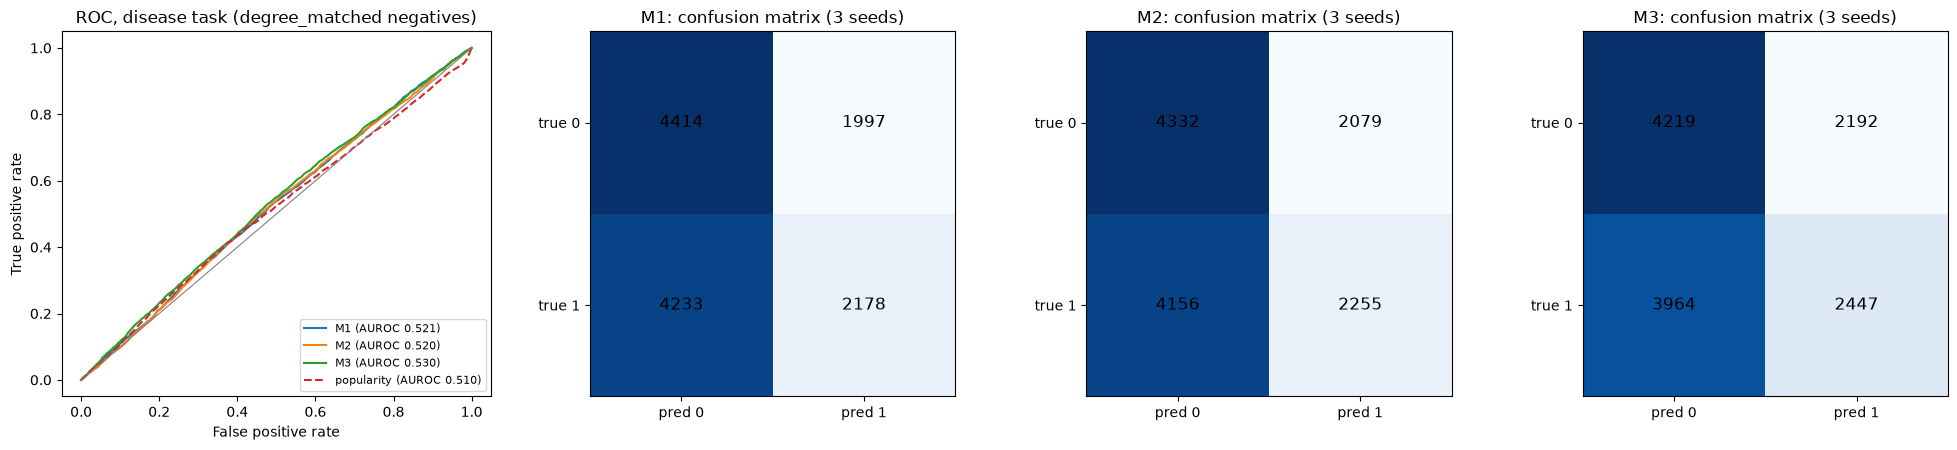

In [7]:
# 08_train - Cell 17: full metric report for existing runs (no retraining):
# ROC curves, AUROC, AUPR, confusion matrix, accuracy, precision, recall (sensitivity), specificity, F1
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix

MODELS_REPORT = ["M1", "M2", "M3"]       # any model names with saved pred_<model>_seed*_fold*.csv files
SCHEME = "degree_matched"                 # primary; set to "random" for the secondary scheme
THRESHOLD = 0.0                           # logit 0 = probability 0.5: the model's own decision boundary, uses no test labels

P = pd.concat([pd.read_csv(f) for m in MODELS_REPORT for f in sorted(OUT.glob(f"pred_{m}_seed*_fold*.csv"))],
              ignore_index=True)
d = P[(P["task"] == "disease") & (P["scheme"] == SCHEME)].copy()
assert set(MODELS_REPORT) <= set(d["model"]), "missing prediction files for some models"

# Popularity-only reference: score = the disease's number of TRAINING pairs in that fold (no circRNA information)
deg = {(s, k): np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=gd.N["disease"])
       for s in sorted(d["seed"].unique()) for k in sorted(d["fold"].unique())}
pop = d[d["model"] == MODELS_REPORT[0]][["seed", "fold", "c", "t", "y"]].copy()
pop["score"] = [deg[(s, k)][t] for s, k, t in zip(pop["seed"], pop["fold"], pop["t"])]
pop["score_rank"] = pop.groupby(["seed", "fold"])["score"].rank(pct=True)
pop["model"] = "popularity"

def metrics(g, with_threshold=True):
    out = {"AUROC": roc_auc_score(g["y"], g["score_rank"]), "AUPR": average_precision_score(g["y"], g["score_rank"])}
    if with_threshold:
        yhat = (g["score"].to_numpy() > THRESHOLD).astype(int)        # each fold's model applies its own boundary
        tn, fp, fn, tp = confusion_matrix(g["y"], yhat, labels=[0, 1]).ravel()
        out.update(TP=tp, FP=fp, TN=tn, FN=fn,
                   Accuracy=(tp + tn) / len(g),
                   Precision=tp / (tp + fp) if tp + fp else np.nan,
                   Recall=tp / (tp + fn) if tp + fn else np.nan,
                   Specificity=tn / (tn + fp) if tn + fp else np.nan,
                   F1=2 * tp / (2 * tp + fp + fn) if tp else 0.0)
    return out

# 1. Metrics per seed (folds pooled), then mean and seed range
rows = []
for m, g_m in pd.concat([d, pop]).groupby("model", sort=False):
    for s, g in g_m.groupby("seed"):
        rows.append({"model": m, "seed": s, **metrics(g, with_threshold=(m != "popularity"))})
per_seed = pd.DataFrame(rows)
cols = [c for c in ["AUROC", "AUPR", "Accuracy", "Precision", "Recall", "Specificity", "F1"] if c in per_seed]
summary = per_seed.groupby("model", sort=False)[cols].agg(["mean", "min", "max"])
table = pd.DataFrame({c: [f"{summary.loc[m, (c, 'mean')]:.3f} ({summary.loc[m, (c, 'min')]:.3f}-{summary.loc[m, (c, 'max')]:.3f})"
                          if pd.notna(summary.loc[m, (c, 'mean')]) else "n/a" for m in summary.index] for c in cols},
                     index=summary.index)
print(f"Disease task, {SCHEME} negatives, threshold = probability 0.5 | mean over seeds (range)")
print(table.to_string())
table.to_csv(OUT / f"report_metrics_{SCHEME}.csv")

# 2. ROC curves: mean over seeds (folds pooled on within-run ranks), popularity as a reference
grid = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 1 + len(MODELS_REPORT), figsize=(5 * (1 + len(MODELS_REPORT)), 4.6))
ax = axes[0]
for m, g_m in pd.concat([d, pop]).groupby("model", sort=False):
    tprs = []
    for s, g in g_m.groupby("seed"):
        fpr, tpr, _ = roc_curve(g["y"], g["score_rank"])
        tprs.append(np.interp(grid, fpr, tpr))
    auc_m = per_seed.loc[per_seed["model"] == m, "AUROC"].mean()
    ax.plot(grid, np.mean(tprs, 0), ls="--" if m == "popularity" else "-", label=f"{m} (AUROC {auc_m:.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"ROC, disease task ({SCHEME} negatives)"); ax.legend(fontsize=8, loc="lower right")

# 3. Confusion matrices: counts summed over the 3 seeds (each pair counted once per seed)
for ax, m in zip(axes[1:], MODELS_REPORT):
    r = per_seed[per_seed["model"] == m][["TN", "FP", "FN", "TP"]].sum()
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"])
    ax.set_title(f"{m}: confusion matrix (3 seeds)")
plt.tight_layout()
plt.savefig(OUT / f"report_roc_confusion_{SCHEME}.png", dpi=200)
plt.show()

Disease task, degree_matched negatives, threshold = probability 0.5 | mean over seeds (range)
                          AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1
model                                                                                                                                                        
M1_hgt      0.526 (0.520-0.535)  0.513 (0.508-0.519)  0.520 (0.511-0.528)  0.524 (0.513-0.534)  0.438 (0.426-0.446)  0.602 (0.596-0.610)  0.477 (0.465-0.486)
M2_hgt      0.526 (0.516-0.538)  0.515 (0.507-0.524)  0.521 (0.514-0.532)  0.525 (0.517-0.538)  0.446 (0.432-0.453)  0.596 (0.581-0.612)  0.482 (0.471-0.492)
M3_hgt      0.529 (0.524-0.536)  0.516 (0.512-0.522)  0.524 (0.519-0.529)  0.527 (0.523-0.535)  0.458 (0.437-0.489)  0.589 (0.556-0.609)  0.490 (0.476-0.506)
popularity  0.510 (0.508-0.513)  0.512 (0.511-0.513)                  n/a                  n/a                  n/a 

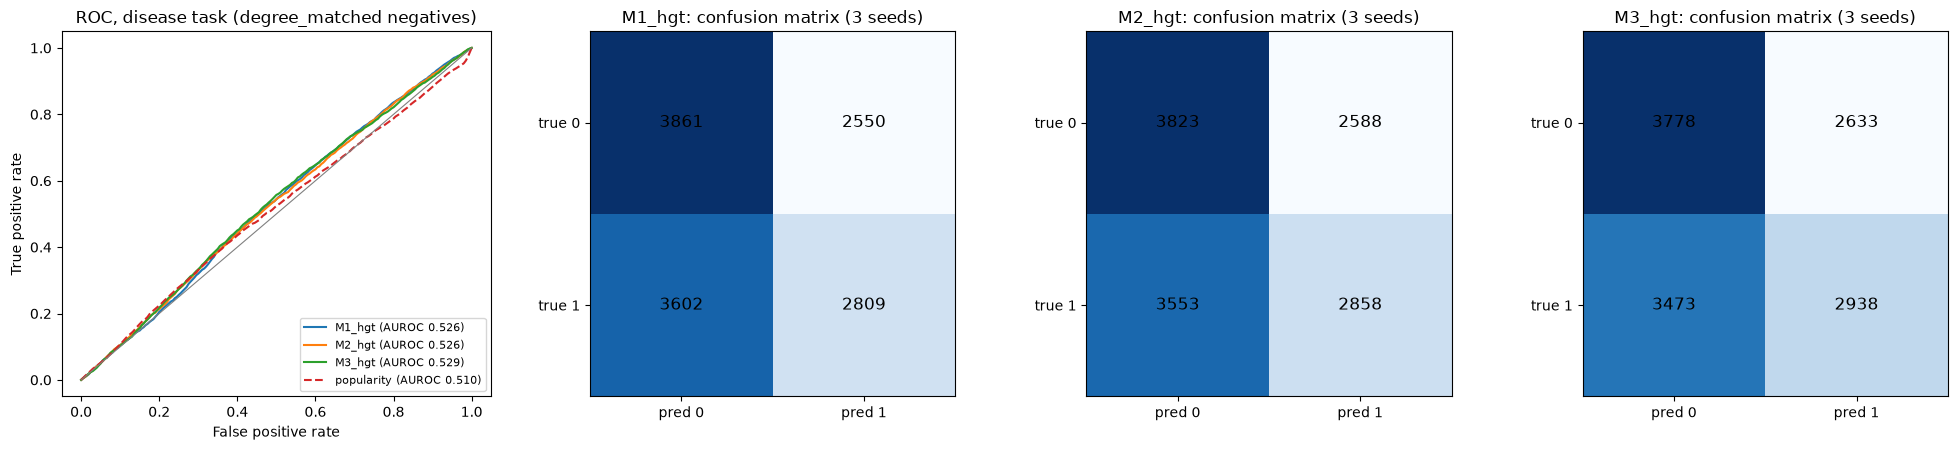

In [8]:
# 08_train - Cell 17: full metric report for existing runs (no retraining):
# ROC curves, AUROC, AUPR, confusion matrix, accuracy, precision, recall (sensitivity), specificity, F1
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix

MODELS_REPORT = ["M1_hgt", "M2_hgt", "M3_hgt"]       # any model names with saved pred_<model>_seed*_fold*.csv files
SCHEME = "degree_matched"                 # primary; set to "random" for the secondary scheme
THRESHOLD = 0.0                           # logit 0 = probability 0.5: the model's own decision boundary, uses no test labels

P = pd.concat([pd.read_csv(f) for m in MODELS_REPORT for f in sorted(OUT.glob(f"pred_{m}_seed*_fold*.csv"))],
              ignore_index=True)
d = P[(P["task"] == "disease") & (P["scheme"] == SCHEME)].copy()
assert set(MODELS_REPORT) <= set(d["model"]), "missing prediction files for some models"

# Popularity-only reference: score = the disease's number of TRAINING pairs in that fold (no circRNA information)
deg = {(s, k): np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=gd.N["disease"])
       for s in sorted(d["seed"].unique()) for k in sorted(d["fold"].unique())}
pop = d[d["model"] == MODELS_REPORT[0]][["seed", "fold", "c", "t", "y"]].copy()
pop["score"] = [deg[(s, k)][t] for s, k, t in zip(pop["seed"], pop["fold"], pop["t"])]
pop["score_rank"] = pop.groupby(["seed", "fold"])["score"].rank(pct=True)
pop["model"] = "popularity"

def metrics(g, with_threshold=True):
    out = {"AUROC": roc_auc_score(g["y"], g["score_rank"]), "AUPR": average_precision_score(g["y"], g["score_rank"])}
    if with_threshold:
        yhat = (g["score"].to_numpy() > THRESHOLD).astype(int)        # each fold's model applies its own boundary
        tn, fp, fn, tp = confusion_matrix(g["y"], yhat, labels=[0, 1]).ravel()
        out.update(TP=tp, FP=fp, TN=tn, FN=fn,
                   Accuracy=(tp + tn) / len(g),
                   Precision=tp / (tp + fp) if tp + fp else np.nan,
                   Recall=tp / (tp + fn) if tp + fn else np.nan,
                   Specificity=tn / (tn + fp) if tn + fp else np.nan,
                   F1=2 * tp / (2 * tp + fp + fn) if tp else 0.0)
    return out

# 1. Metrics per seed (folds pooled), then mean and seed range
rows = []
for m, g_m in pd.concat([d, pop]).groupby("model", sort=False):
    for s, g in g_m.groupby("seed"):
        rows.append({"model": m, "seed": s, **metrics(g, with_threshold=(m != "popularity"))})
per_seed = pd.DataFrame(rows)
cols = [c for c in ["AUROC", "AUPR", "Accuracy", "Precision", "Recall", "Specificity", "F1"] if c in per_seed]
summary = per_seed.groupby("model", sort=False)[cols].agg(["mean", "min", "max"])
table = pd.DataFrame({c: [f"{summary.loc[m, (c, 'mean')]:.3f} ({summary.loc[m, (c, 'min')]:.3f}-{summary.loc[m, (c, 'max')]:.3f})"
                          if pd.notna(summary.loc[m, (c, 'mean')]) else "n/a" for m in summary.index] for c in cols},
                     index=summary.index)
print(f"Disease task, {SCHEME} negatives, threshold = probability 0.5 | mean over seeds (range)")
print(table.to_string())
table.to_csv(OUT / f"report_metrics_{SCHEME}.csv")

# 2. ROC curves: mean over seeds (folds pooled on within-run ranks), popularity as a reference
grid = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 1 + len(MODELS_REPORT), figsize=(5 * (1 + len(MODELS_REPORT)), 4.6))
ax = axes[0]
for m, g_m in pd.concat([d, pop]).groupby("model", sort=False):
    tprs = []
    for s, g in g_m.groupby("seed"):
        fpr, tpr, _ = roc_curve(g["y"], g["score_rank"])
        tprs.append(np.interp(grid, fpr, tpr))
    auc_m = per_seed.loc[per_seed["model"] == m, "AUROC"].mean()
    ax.plot(grid, np.mean(tprs, 0), ls="--" if m == "popularity" else "-", label=f"{m} (AUROC {auc_m:.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"ROC, disease task ({SCHEME} negatives)"); ax.legend(fontsize=8, loc="lower right")

# 3. Confusion matrices: counts summed over the 3 seeds (each pair counted once per seed)
for ax, m in zip(axes[1:], MODELS_REPORT):
    r = per_seed[per_seed["model"] == m][["TN", "FP", "FN", "TP"]].sum()
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"])
    ax.set_title(f"{m}: confusion matrix (3 seeds)")
plt.tight_layout()
plt.savefig(OUT / f"report_roc_confusion_{SCHEME}.png", dpi=200)
plt.show()

Disease task, degree_matched negatives, threshold = probability 0.5 | mean over seeds (range)
                          AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1
model                                                                                                                                                        
M1_mesh     0.530 (0.529-0.530)  0.523 (0.519-0.526)  0.519 (0.515-0.524)  0.527 (0.523-0.531)  0.373 (0.326-0.414)  0.665 (0.635-0.703)  0.436 (0.402-0.465)
M2_mesh     0.531 (0.518-0.539)  0.523 (0.518-0.530)  0.519 (0.509-0.530)  0.528 (0.515-0.543)  0.352 (0.318-0.380)  0.686 (0.679-0.700)  0.422 (0.393-0.447)
M3_mesh     0.534 (0.525-0.540)  0.523 (0.514-0.529)  0.522 (0.520-0.526)  0.531 (0.526-0.536)  0.376 (0.337-0.403)  0.668 (0.636-0.703)  0.440 (0.413-0.457)
popularity  0.510 (0.508-0.513)  0.512 (0.511-0.513)                  n/a                  n/a                  n/a 

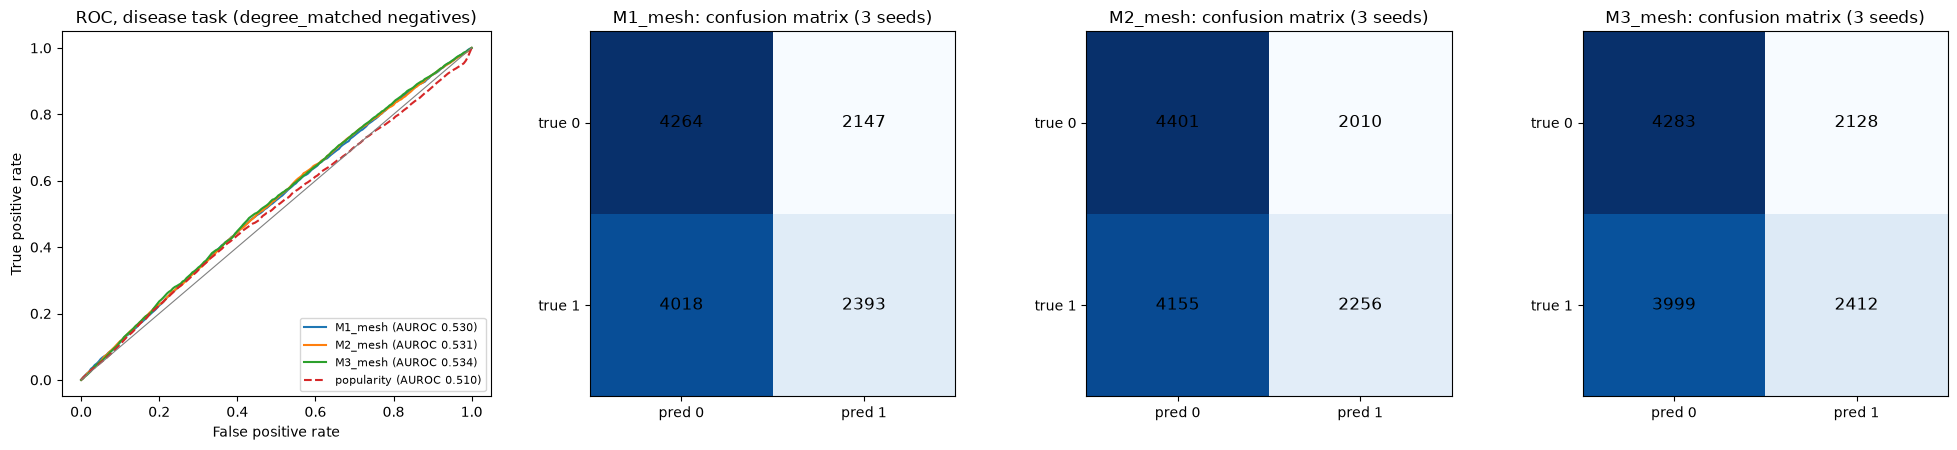

In [9]:
# 08_train - Cell 17: full metric report for existing runs (no retraining):
# ROC curves, AUROC, AUPR, confusion matrix, accuracy, precision, recall (sensitivity), specificity, F1
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix

MODELS_REPORT = ["M1_mesh", "M2_mesh", "M3_mesh"]       # any model names with saved pred_<model>_seed*_fold*.csv files
SCHEME = "degree_matched"                 # primary; set to "random" for the secondary scheme
THRESHOLD = 0.0                           # logit 0 = probability 0.5: the model's own decision boundary, uses no test labels

P = pd.concat([pd.read_csv(f) for m in MODELS_REPORT for f in sorted(OUT.glob(f"pred_{m}_seed*_fold*.csv"))],
              ignore_index=True)
d = P[(P["task"] == "disease") & (P["scheme"] == SCHEME)].copy()
assert set(MODELS_REPORT) <= set(d["model"]), "missing prediction files for some models"

# Popularity-only reference: score = the disease's number of TRAINING pairs in that fold (no circRNA information)
deg = {(s, k): np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=gd.N["disease"])
       for s in sorted(d["seed"].unique()) for k in sorted(d["fold"].unique())}
pop = d[d["model"] == MODELS_REPORT[0]][["seed", "fold", "c", "t", "y"]].copy()
pop["score"] = [deg[(s, k)][t] for s, k, t in zip(pop["seed"], pop["fold"], pop["t"])]
pop["score_rank"] = pop.groupby(["seed", "fold"])["score"].rank(pct=True)
pop["model"] = "popularity"

def metrics(g, with_threshold=True):
    out = {"AUROC": roc_auc_score(g["y"], g["score_rank"]), "AUPR": average_precision_score(g["y"], g["score_rank"])}
    if with_threshold:
        yhat = (g["score"].to_numpy() > THRESHOLD).astype(int)        # each fold's model applies its own boundary
        tn, fp, fn, tp = confusion_matrix(g["y"], yhat, labels=[0, 1]).ravel()
        out.update(TP=tp, FP=fp, TN=tn, FN=fn,
                   Accuracy=(tp + tn) / len(g),
                   Precision=tp / (tp + fp) if tp + fp else np.nan,
                   Recall=tp / (tp + fn) if tp + fn else np.nan,
                   Specificity=tn / (tn + fp) if tn + fp else np.nan,
                   F1=2 * tp / (2 * tp + fp + fn) if tp else 0.0)
    return out

# 1. Metrics per seed (folds pooled), then mean and seed range
rows = []
for m, g_m in pd.concat([d, pop]).groupby("model", sort=False):
    for s, g in g_m.groupby("seed"):
        rows.append({"model": m, "seed": s, **metrics(g, with_threshold=(m != "popularity"))})
per_seed = pd.DataFrame(rows)
cols = [c for c in ["AUROC", "AUPR", "Accuracy", "Precision", "Recall", "Specificity", "F1"] if c in per_seed]
summary = per_seed.groupby("model", sort=False)[cols].agg(["mean", "min", "max"])
table = pd.DataFrame({c: [f"{summary.loc[m, (c, 'mean')]:.3f} ({summary.loc[m, (c, 'min')]:.3f}-{summary.loc[m, (c, 'max')]:.3f})"
                          if pd.notna(summary.loc[m, (c, 'mean')]) else "n/a" for m in summary.index] for c in cols},
                     index=summary.index)
print(f"Disease task, {SCHEME} negatives, threshold = probability 0.5 | mean over seeds (range)")
print(table.to_string())
table.to_csv(OUT / f"report_metrics_{SCHEME}.csv")

# 2. ROC curves: mean over seeds (folds pooled on within-run ranks), popularity as a reference
grid = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 1 + len(MODELS_REPORT), figsize=(5 * (1 + len(MODELS_REPORT)), 4.6))
ax = axes[0]
for m, g_m in pd.concat([d, pop]).groupby("model", sort=False):
    tprs = []
    for s, g in g_m.groupby("seed"):
        fpr, tpr, _ = roc_curve(g["y"], g["score_rank"])
        tprs.append(np.interp(grid, fpr, tpr))
    auc_m = per_seed.loc[per_seed["model"] == m, "AUROC"].mean()
    ax.plot(grid, np.mean(tprs, 0), ls="--" if m == "popularity" else "-", label=f"{m} (AUROC {auc_m:.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"ROC, disease task ({SCHEME} negatives)"); ax.legend(fontsize=8, loc="lower right")

# 3. Confusion matrices: counts summed over the 3 seeds (each pair counted once per seed)
for ax, m in zip(axes[1:], MODELS_REPORT):
    r = per_seed[per_seed["model"] == m][["TN", "FP", "FN", "TP"]].sum()
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"])
    ax.set_title(f"{m}: confusion matrix (3 seeds)")
plt.tight_layout()
plt.savefig(OUT / f"report_roc_confusion_{SCHEME}.png", dpi=200)
plt.show()

Disease task, degree_matched negatives, threshold = probability 0.5 | mean over seeds (range)
                          AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1
model                                                                                                                                                        
M1_nolen    0.521 (0.516-0.529)  0.511 (0.504-0.515)  0.511 (0.504-0.515)  0.517 (0.507-0.522)  0.330 (0.315-0.338)  0.691 (0.688-0.694)  0.403 (0.389-0.410)
M3_nolen    0.532 (0.527-0.542)  0.522 (0.510-0.534)  0.523 (0.516-0.531)  0.532 (0.521-0.546)  0.382 (0.365-0.395)  0.663 (0.644-0.697)  0.445 (0.437-0.452)
popularity  0.510 (0.508-0.513)  0.512 (0.511-0.513)                  n/a                  n/a                  n/a                  n/a                  n/a


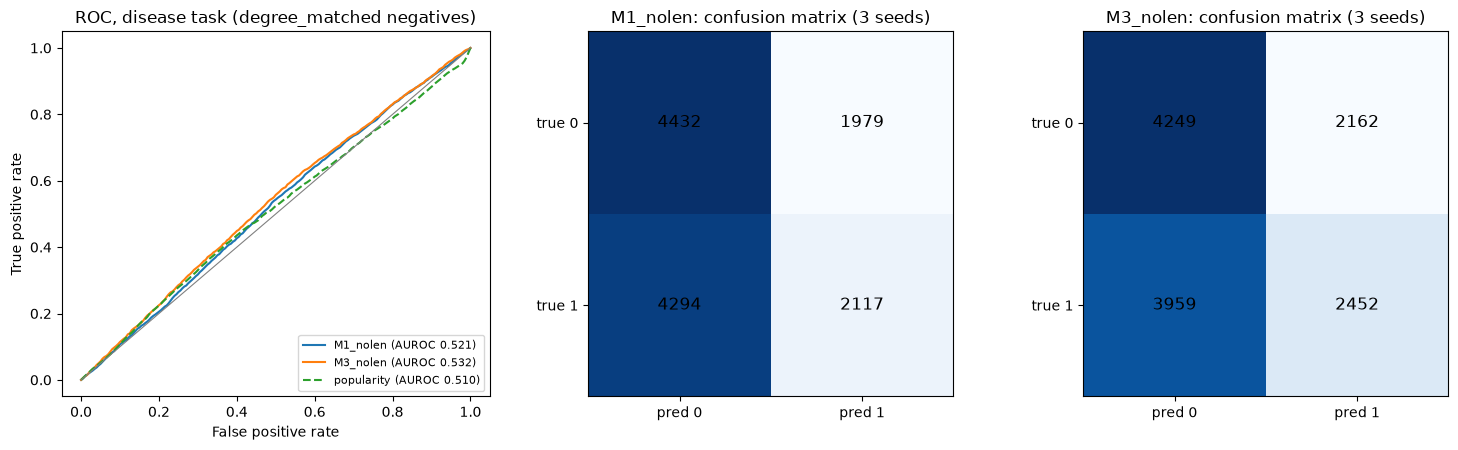

In [11]:
# 08_train - Cell 17: full metric report for existing runs (no retraining):
# ROC curves, AUROC, AUPR, confusion matrix, accuracy, precision, recall (sensitivity), specificity, F1
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix

MODELS_REPORT = ["M1_nolen", "M3_nolen"]       # any model names with saved pred_<model>_seed*_fold*.csv files
SCHEME = "degree_matched"                 # primary; set to "random" for the secondary scheme
THRESHOLD = 0.0                           # logit 0 = probability 0.5: the model's own decision boundary, uses no test labels

P = pd.concat([pd.read_csv(f) for m in MODELS_REPORT for f in sorted(OUT.glob(f"pred_{m}_seed*_fold*.csv"))],
              ignore_index=True)
d = P[(P["task"] == "disease") & (P["scheme"] == SCHEME)].copy()
assert set(MODELS_REPORT) <= set(d["model"]), "missing prediction files for some models"

# Popularity-only reference: score = the disease's number of TRAINING pairs in that fold (no circRNA information)
deg = {(s, k): np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=gd.N["disease"])
       for s in sorted(d["seed"].unique()) for k in sorted(d["fold"].unique())}
pop = d[d["model"] == MODELS_REPORT[0]][["seed", "fold", "c", "t", "y"]].copy()
pop["score"] = [deg[(s, k)][t] for s, k, t in zip(pop["seed"], pop["fold"], pop["t"])]
pop["score_rank"] = pop.groupby(["seed", "fold"])["score"].rank(pct=True)
pop["model"] = "popularity"

def metrics(g, with_threshold=True):
    out = {"AUROC": roc_auc_score(g["y"], g["score_rank"]), "AUPR": average_precision_score(g["y"], g["score_rank"])}
    if with_threshold:
        yhat = (g["score"].to_numpy() > THRESHOLD).astype(int)        # each fold's model applies its own boundary
        tn, fp, fn, tp = confusion_matrix(g["y"], yhat, labels=[0, 1]).ravel()
        out.update(TP=tp, FP=fp, TN=tn, FN=fn,
                   Accuracy=(tp + tn) / len(g),
                   Precision=tp / (tp + fp) if tp + fp else np.nan,
                   Recall=tp / (tp + fn) if tp + fn else np.nan,
                   Specificity=tn / (tn + fp) if tn + fp else np.nan,
                   F1=2 * tp / (2 * tp + fp + fn) if tp else 0.0)
    return out

# 1. Metrics per seed (folds pooled), then mean and seed range
rows = []
for m, g_m in pd.concat([d, pop]).groupby("model", sort=False):
    for s, g in g_m.groupby("seed"):
        rows.append({"model": m, "seed": s, **metrics(g, with_threshold=(m != "popularity"))})
per_seed = pd.DataFrame(rows)
cols = [c for c in ["AUROC", "AUPR", "Accuracy", "Precision", "Recall", "Specificity", "F1"] if c in per_seed]
summary = per_seed.groupby("model", sort=False)[cols].agg(["mean", "min", "max"])
table = pd.DataFrame({c: [f"{summary.loc[m, (c, 'mean')]:.3f} ({summary.loc[m, (c, 'min')]:.3f}-{summary.loc[m, (c, 'max')]:.3f})"
                          if pd.notna(summary.loc[m, (c, 'mean')]) else "n/a" for m in summary.index] for c in cols},
                     index=summary.index)
print(f"Disease task, {SCHEME} negatives, threshold = probability 0.5 | mean over seeds (range)")
print(table.to_string())
table.to_csv(OUT / f"report_metrics_{SCHEME}.csv")

# 2. ROC curves: mean over seeds (folds pooled on within-run ranks), popularity as a reference
grid = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 1 + len(MODELS_REPORT), figsize=(5 * (1 + len(MODELS_REPORT)), 4.6))
ax = axes[0]
for m, g_m in pd.concat([d, pop]).groupby("model", sort=False):
    tprs = []
    for s, g in g_m.groupby("seed"):
        fpr, tpr, _ = roc_curve(g["y"], g["score_rank"])
        tprs.append(np.interp(grid, fpr, tpr))
    auc_m = per_seed.loc[per_seed["model"] == m, "AUROC"].mean()
    ax.plot(grid, np.mean(tprs, 0), ls="--" if m == "popularity" else "-", label=f"{m} (AUROC {auc_m:.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"ROC, disease task ({SCHEME} negatives)"); ax.legend(fontsize=8, loc="lower right")

# 3. Confusion matrices: counts summed over the 3 seeds (each pair counted once per seed)
for ax, m in zip(axes[1:], MODELS_REPORT):
    r = per_seed[per_seed["model"] == m][["TN", "FP", "FN", "TP"]].sum()
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"])
    ax.set_title(f"{m}: confusion matrix (3 seeds)")
plt.tight_layout()
plt.savefig(OUT / f"report_roc_confusion_{SCHEME}.png", dpi=200)
plt.show()

## Cell 18

In [18]:
# 08_train - Cell 18: wiring check (diagnostic only, never a result).
# If the test disease edges are placed IN the graph, M1 must score them far above 0.53; otherwise the relation is mis-wired.
fd = gd.load_fold(0, 0)
model, x, hist, best = train_one(fd, "M1", seed=0)
rel = gd.inference_graph(fd, "test", "M1")
leak = {**rel, "disease": np.vstack([rel["disease"], fd["disease_test"]])}
for name, r in [("normal graph (as in all results)", rel), ("test disease edges ADDED (check only)", leak)]:
    with torch.no_grad():
        h = model.encode(x, *gd.to_edge_tensors(r, device))
        au, ap, *_ = score_pairs(model, h, "disease", fd["disease_test"], fd["neg_test_degree_matched"])
    print(f"{name:40s} AUROC {au:.3f}")

C:\Users\aeasa\AppData\Local\Temp\ipykernel_34672\2136109673.py:47: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  hist.append({"epoch": epoch, "loss": float(loss), **{f"loss_{r}": v for r, v in parts.items()}, "val_auc": va})


normal graph (as in all results)         AUROC 0.510
test disease edges ADDED (check only)    AUROC 0.528


## cell 19

In [19]:
# 08_train - Cell 19: positive control (diagnostic only, never a result).
# Plant a disease label that IS in the circRNA features; a working pipeline must learn it under the strict protocol.
from circmtl.graph import _codes
rng_pc = np.random.default_rng(123)
N_C, N_D = gd.N["circRNA"], gd.N["disease"]
Z = (gd.X_raw - gd.X_raw.mean(0)) / (gd.X_raw.std(0) + 1e-8)                 # label-free standardisation
R = rng_pc.normal(size=(Z.shape[1], N_D)) / np.sqrt(Z.shape[1])
pop = np.bincount(gd.E["disease"][:, 1], minlength=N_D) + 1.0
syn_d = np.argmax(Z @ R + 0.5 * np.log(pop), axis=1)                         # one synthetic disease per circRNA
E_syn = np.c_[np.arange(N_C), syn_d].astype(np.int64)

def synthetic_fold(fd):
    out = dict(fd)
    for part in ("train", "val", "test"):
        out[f"disease_{part}"] = E_syn[np.isin(E_syn[:, 0], fd[part])]
    cnt = np.bincount(out["disease_train"][:, 1], minlength=N_D).astype(float)
    def neg(pos, seed, p):
        r = np.random.default_rng(seed); t = r.choice(N_D, size=len(pos), p=p)
        bad = t == pos[:, 1]
        while bad.any():
            t[bad] = r.choice(N_D, size=int(bad.sum()), p=p); bad = t == pos[:, 1]
        return np.c_[pos[:, 0], t].astype(np.int64)
    p_deg, p_uni = cnt / cnt.sum(), np.full(N_D, 1.0 / N_D)
    out["neg_val"] = neg(out["disease_val"], 1, p_deg)
    out["neg_test_degree_matched"] = neg(out["disease_test"], 2, p_deg)
    out["neg_test_random"] = neg(out["disease_test"], 3, p_uni)
    return out

real_known = gd.known_codes["disease"]
gd.known_codes["disease"] = np.unique(_codes(E_syn[:, 0], E_syn[:, 1], N_D))   # training negatives avoid synthetic positives
try:
    fd_syn = synthetic_fold(gd.load_fold(0, 0))
    model, x, hist, best = train_one(fd_syn, "M1", seed=0)
    res = evaluate(model, x, fd_syn, "M1")
finally:
    gd.known_codes["disease"] = real_known                                     # always restore the real labels
print(f"planted signal, M1, seed 0 fold 0: best epoch {best['epoch']} | val {best['auc']:.3f} | "
      f"test degree-matched {res['disease_degree_matched_auroc']:.3f} | random {res['disease_random_auroc']:.3f}")

planted signal, M1, seed 0 fold 0: best epoch 56 | val 0.939 | test degree-matched 0.941 | random 0.882
